In [1]:
import sys
print(sys.executable)

C:\Users\hp\OneDrive\Desktop\Finance\.venv\Scripts\python.exe


In [93]:
import torch
print("torch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

torch version: 2.6.0+cu124
GPU available: True
GPU name: NVIDIA GeForce RTX 3050 Laptop GPU
GPU memory (GB): 4.3


In [3]:
import sys
!{sys.executable} -m pip install google-play-scraper pandas

  Using cached google_play_scraper-1.2.7-py3-none-any.whl.metadata (50 kB)
Using cached google_play_scraper-1.2.7-py3-none-any.whl (28 kB)



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: C:\Users\hp\OneDrive\Desktop\Finance\.venv\Scripts\python.exe -m pip install --upgrade pip


In [7]:
#importing library

In [35]:
import time
import re
import textwrap
from datetime import datetime, timedelta
 
import pandas as pd
from google_play_scraper import Sort, reviews

In [2]:
APP_ID = "in.swiggy.android"      # verify on the Play Store URL
APP_NAME = "swiggy"
COUNTRY = "in"
LANGUAGES = ["en", "hi"]          # Hinglish mostly shows up under "en"
MAX_REVIEWS_PER_LANG = 60000      # safety cap; the date cutoff should stop us first
MONTHS_BACK = 3                   # keep only the last N months
BATCH_SIZE = 200
PAUSE_SECONDS = 1.0               # be polite to the server
OUT_FILE = f"data/raw_{APP_NAME}_reviews.csv"

In [3]:
def fetch_language(lang, cutoff):
    """Pull newest-first reviews for one language until we hit the cutoff date."""
    collected = []
    token = None
 
    while len(collected) < MAX_REVIEWS_PER_LANG:
        batch, token = reviews(
            APP_ID,
            lang=lang,
            country=COUNTRY,
            sort=Sort.NEWEST,
            count=BATCH_SIZE,
            continuation_token=token,
        )
        if not batch:
            break
 
        collected.extend(batch)
        oldest = min(r["at"] for r in batch)
        print(f"[{lang}] {len(collected)} reviews so far, oldest: {oldest:%Y-%m-%d}")
 
        if oldest < cutoff or token is None:
            break
        time.sleep(PAUSE_SECONDS)
 
    if collected:
        oldest_all = min(r["at"] for r in collected)
        if oldest_all >= cutoff:
            print(f"WARNING [{lang}]: stopped at {oldest_all:%Y-%m-%d}, which is newer "
                  f"than the cutoff {cutoff:%Y-%m-%d}. Raise MAX_REVIEWS_PER_LANG.")
 
    return collected

In [7]:
def main():
    cutoff = datetime.now() - timedelta(days=30 * MONTHS_BACK)
    rows = []
    for lang in LANGUAGES:
        for r in fetch_language(lang, cutoff):
            r["fetched_lang"] = lang
            rows.append(r)
 
    df = pd.DataFrame(rows)
    if df.empty:
        print("No reviews fetched. Check APP_ID and your internet connection.")
        return
 
    # Keep only what we need. Dropping usernames and profile pictures
    # keeps the dataset free of personal information.
    keep = {
        "reviewId": "review_id",
        "content": "text",
        "score": "rating",
        "thumbsUpCount": "thumbs_up",
        "appVersion": "app_version",
        "at": "date",
        "replyContent": "reply_text",
        "repliedAt": "reply_date",
        "fetched_lang": "fetched_lang",
    }
    df = df[[c for c in keep if c in df.columns]].rename(columns=keep)
 
    # Clean basics
    df = df.drop_duplicates(subset="review_id")
    df = df[df["text"].notna() & (df["text"].str.strip() != "")]
    df["date"] = pd.to_datetime(df["date"])
    df = df[df["date"] >= cutoff].sort_values("date").reset_index(drop=True)
 
    import os
    os.makedirs(os.path.dirname(OUT_FILE), exist_ok=True)
    df.to_csv(OUT_FILE, index=False, encoding="utf-8")
 
    print("\nSaved:", OUT_FILE)
    print("Reviews:", len(df))
    print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
    print("Rating counts:\n", df["rating"].value_counts().sort_index())
 
    # Reviews per week: do we have enough for smooth weekly trends?
    weekly = df.set_index("date").resample("W").size()
    print("\nReviews per week:\n", weekly.to_string())
 
    # Text quality: how many reviews are too short to be useful?
    words = df["text"].str.split().str.len()
    letters_re = re.compile(r"[A-Za-z\u0900-\u097F]")
    devanagari_re = re.compile(r"[\u0900-\u097F]")
    good_words_re = re.compile(r"\b(?:good|best|nice|great)\b")
    texts = df["text"].astype(str)
    has_letters = texts.apply(lambda s: bool(letters_re.search(s)))
    print("\nReviews with 3 words or fewer:", f"{(words <= 3).mean():.1%}")
    print("Reviews with 8+ words:", f"{(words >= 8).mean():.1%}")
    print("Emoji/symbol-only reviews:", f"{(~has_letters).mean():.1%}")
    devanagari_share = texts.apply(lambda s: bool(devanagari_re.search(s))).mean()
    print("Reviews containing Devanagari (Hindi script):", f"{devanagari_share:.1%}")
 
    # Do star ratings match the text? (1-star reviews saying 'good' = label noise)
    says_good = texts.str.lower().apply(lambda s: bool(good_words_re.search(s)))
    one_star_good = df[(df["rating"] == 1) & says_good]
    print("1-star reviews containing good/best/nice/great:", len(one_star_good))
    print("\nSample reviews:")
    print(df[["date", "rating", "text"]].sample(min(10, len(df)), random_state=1).to_string())
 
 
if __name__ == "__main__":
    main()
 

[en] 200 reviews so far, oldest: 2026-10-08
[en] 400 reviews so far, oldest: 2026-10-08
[en] 600 reviews so far, oldest: 2026-10-07
[en] 800 reviews so far, oldest: 2026-10-07
[en] 1000 reviews so far, oldest: 2026-10-06
[en] 1200 reviews so far, oldest: 2026-10-06
[en] 1400 reviews so far, oldest: 2026-10-05
[en] 1600 reviews so far, oldest: 2026-10-05
[en] 1800 reviews so far, oldest: 2026-10-04
[en] 2000 reviews so far, oldest: 2026-10-04
[en] 2200 reviews so far, oldest: 2026-10-03
[en] 2400 reviews so far, oldest: 2026-10-03
[en] 2600 reviews so far, oldest: 2026-10-03
[en] 2800 reviews so far, oldest: 2026-10-02
[en] 3000 reviews so far, oldest: 2026-10-02
[en] 3200 reviews so far, oldest: 2026-10-01
[en] 3400 reviews so far, oldest: 2026-09-30
[en] 3600 reviews so far, oldest: 2026-09-30
[en] 3800 reviews so far, oldest: 2026-09-29
[en] 4000 reviews so far, oldest: 2026-09-29
[en] 4200 reviews so far, oldest: 2026-09-28
[en] 4400 reviews so far, oldest: 2026-09-27
[en] 4600 revi

In [9]:
#EDA

In [13]:
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

df = pd.read_csv("data/raw_swiggy_reviews.csv", parse_dates=["date"])
df["text"] = df["text"].astype(str)
df["n_words"] = df["text"].str.split().str.len()

HINDI = {"hai", "hain", "nahi", "nhi", "nahin", "bahut", "bohot", "bhut", "kya", "kyu",
         "mera", "meri", "mere", "aap", "acha", "accha", "achha", "bekar", "bakwas",
         "kharab", "khana", "paisa", "paise", "jaldi", "ghatiya", "wala", "wali", "tha",
         "thi", "abhi", "kuch", "bhai", "yaar", "yeh", "lekin", "bilkul", "zyada", "diya",
         "liya", "mila"}
hits = df["text"].apply(lambda s: sum(t in HINDI for t in re.findall(r"[a-z]+", s.lower())))
longer = df["n_words"] >= 4

print("1+ Hindi word, all reviews:", f"{(hits >= 1).mean():.1%}")

1+ Hindi word, all reviews: 3.9%


In [15]:
print("1+ Hindi word, 4+ word reviews:", f"{(hits[longer] >= 1).mean():.1%}")

1+ Hindi word, 4+ word reviews: 8.3%


In [17]:
print("2+ Hindi words, 4+ word reviews:", f"{(hits[longer] >= 2).mean():.1%}")

2+ Hindi words, 4+ word reviews: 5.2%


In [19]:
cand = df[longer & (hits >= 1)]
print(cand.sample(min(25, len(cand)), random_state=1)[["rating", "text"]].to_string())

       rating                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               text
2253        4                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   just wo

In [21]:
#here saw that 22 out of 25 are hindienglish language 

In [23]:
#also show important like for whethere it is "App" or "AAP"
#Spelling is also messy like "bhot, bhut, bohot, jada, jyada, jldi, nhi, achcha, achha, pese, paise"
#mixed scripts - फिर app par show ही kyu kar रखा hai
# Star ratings are noisy

In [ ]:
#text cleaning and preprocessing the text column

In [29]:
df = pd.read_csv("data/raw_swiggy_reviews.csv", parse_dates=["date"])
df["text"] = df["text"].astype(str).str.replace("\u2019", "'", regex=False) #remove the unwanted text ("\u2019")

#define a cleaning function
def clean(s):
    s = re.sub(r"https?://\S+", " ", s.lower())  #url matching are replaced to space and making letter in lower case 
    s = re.sub(r"(.)\1{2,}", r"\1\1", s)   # wowwwww -> woww
    return re.sub(r"\s+", " ", s).strip()   #remove extra space 

df["clean_text"] = df["text"].apply(clean)  #run this function on each review 
changed = df[df["text"].str.lower() != df["clean_text"]]    #result stored in new column

In [31]:
print("Reviews changed by cleaning:", len(changed), "of", len(df))

Reviews changed by cleaning: 1819 of 39457


In [43]:
# approximately 4.6% is clean

In [45]:
# To see before and after 

In [47]:
demo = changed[changed["text"].str.len() <= 200]      # short ones read best
demo = demo.sample(min(8, len(demo)), random_state=1)

def show(label, s):
    print(textwrap.fill(s, width=90, initial_indent=f"  {label}: ", subsequent_indent=" " * (len(label) + 4)))

for i, row in demo.iterrows():
    print(f"Review #{i} | rating {row['rating']}")
    show("Before", row["text"])
    show("After ", row["clean_text"])
    print("-" * 90)

Review #9071 | rating 5
  Before: 🔥🔥🔥
  After : 🔥🔥
------------------------------------------------------------------------------------------
Review #15420 | rating 5
  Before: excellent offer 🥰🥰🥰🥰
  After : excellent offer 🥰🥰
------------------------------------------------------------------------------------------
Review #30535 | rating 1
  Before: Delivery charges are too High........ use another app like Zo****
  After : delivery charges are too high.. use another app like zo**
------------------------------------------------------------------------------------------
Review #28630 | rating 5
  Before: goood
  After : good
------------------------------------------------------------------------------------------
Review #4232 | rating 5
  Before: why instamart not available...
  After : why instamart not available..
------------------------------------------------------------------------------------------
Review #34194 | rating 1
  Before: restaurant and gst minimum 55 and 65 jitna k

In [ ]:
# wanted to select randomly 10 also

In [49]:
for i, row in changed[["text", "clean_text"]].sample(
    min(10, len(changed)), random_state=1
).iterrows():

    print(f"\n{'=' * 70}")
    print(f"Review {i}")
    print("-" * 70)
    print("BEFORE CLEANING:")
    print(row["text"])
    print("\nAFTER CLEANING:")
    print(row["clean_text"])
    print("=" * 70)


Review 38959
----------------------------------------------------------------------
BEFORE CLEANING:
good 😊😊😊😊😊😊😊😊😊😊😊😊😊😊

AFTER CLEANING:
good 😊😊

Review 20975
----------------------------------------------------------------------
BEFORE CLEANING:
wrost swiggy.... zomato is best

AFTER CLEANING:
wrost swiggy.. zomato is best

Review 11499
----------------------------------------------------------------------
BEFORE CLEANING:
Why did the app even Start the event of Buzz Streak and after 3 days now it is not able to open..... And even after applying offer the gst consumes most of the money amounts..... Which restaurant takes packaging price... while in person when we go in hotel and order they take zero packaging.... but in Swiggy the same hotel asks for 15 rupees and also there is a restaurant gst added as well... which make no sense... as the same hotel in person when we go to eat, they don't even mention this....

AFTER CLEANING:
why did the app even start the event of buzz streak an

In [51]:
# in these relaised that 3000 also become 300 lol

In [53]:
# Fix: the old rule also shortened repeated digits (3000 -> 300). New version never touches digits.
def clean(s):
    s = re.sub(r"https?://\S+", " ", s.lower())
    s = re.sub(r"([^\W\d_])\1{2,}", r"\1\1", s)   # letters only: wowwwww -> woww
    s = re.sub(r"([^\w\s])\1{2,}", r"\1\1", s)    # symbols/emoji: !!!!! -> !!
    return re.sub(r"\s+", " ", s).strip()

df["clean_text_old"] = df["clean_text"]           # keep the old result to compare
df["clean_text"] = df["text"].apply(clean)

digits = lambda s: re.findall(r"\d+", s)
bug = df[df["text"].apply(digits) != df["clean_text_old"].apply(digits)]
print("Reviews where the OLD cleaning changed a number:", len(bug))
print("Reviews where the NEW cleaning changed a number:",
      int((df["text"].apply(digits) != df["clean_text"].apply(digits)).sum()))

for i, row in bug.head(3).iterrows():
    print(f"\nReview #{i}")
    show("Original", row["text"])
    show("Old     ", row["clean_text_old"])
    show("New     ", row["clean_text"])

Reviews where the OLD cleaning changed a number: 51
Reviews where the NEW cleaning changed a number: 0

Review #465
  Original: They have my Rs. 2000 which was supposed to be refunded but they did not and
            you can only guess how bad their customer service is. After a month talking to
            them on email they said "We have verified your claim, and a refund of
            Rs.2000/- has been credited to your source account." but i never received the
            amount till date.
  Old     : they have my rs. 200 which was supposed to be refunded but they did not and
            you can only guess how bad their customer service is. after a month talking to
            them on email they said "we have verified your claim, and a refund of rs.200/-
            has been credited to your source account." but i never received the amount
            till date.
  New     : they have my rs. 2000 which was supposed to be refunded but they did not and
            you can only guess ho

In [56]:
# language detection (Hindi, Hinglish, English)

In [58]:
# Find the hindi words mostly used in review

In [70]:
# Find the most common non-English words in the reviews (candidates for the Hindi word list)
from collections import Counter
import nltk
nltk.download("words", quiet=True)
from nltk.corpus import words

english = set(w.lower() for w in words.words())
counts = Counter(t for s in df["clean_text"] for t in re.findall(r"[a-z]+", s))
unknown = [(w, c) for w, c in counts.most_common() if w not in english and len(w) > 1]

print(unknown[:500])

[('app', 6121), ('swiggy', 4688), ('hai', 1222), ('delivered', 1018), ('has', 725), ('zomato', 716), ('charges', 699), ('items', 683), ('orders', 605), ('minutes', 582), ('didn', 566), ('instamart', 545), ('customers', 525), ('cancelled', 499), ('rs', 422), ('offers', 407), ('hours', 405), ('mins', 376), ('ordering', 354), ('placed', 353), ('bhi', 324), ('aap', 316), ('using', 299), ('paid', 278), ('ke', 275), ('delayed', 269), ('services', 266), ('nhi', 262), ('apps', 253), ('pm', 248), ('nahi', 242), ('doesn', 241), ('gst', 223), ('delivering', 220), ('asked', 217), ('guys', 217), ('aur', 215), ('issues', 214), ('charged', 205), ('email', 203), ('partners', 201), ('shows', 199), ('fees', 199), ('prices', 193), ('online', 192), ('ki', 185), ('rupees', 174), ('restaurants', 173), ('products', 173), ('ve', 163), ('takes', 159), ('kiya', 158), ('called', 153), ('frustrating', 149), ('kar', 149), ('happened', 141), ('refused', 139), ('bekar', 137), ('okay', 134), ('km', 133), ('agents', 1

In [ ]:
# Word list (strict)(rule based language detection) 

In [83]:
# Word-list language tagger (the baseline we'll compare the model against)
HINDI = {
    "hai","hain","bhi","ke","ka","ki","ko","se","pe","par","aur","nhi","nahi","nahin",
    "kar","kr","kiya","kiye","raha","rahi","rahe","ek","khana","bekar","bhot","bhut",
    "bohot","bahut","jldi","paise","pese","mera","mere","meri","bhai","achha","accha",
    "kuch","koi","mat","liya","diya","wala","wale","tha","thi","abhi","bilkul","sirf",
    "ho","hua","gaya","gayi","lekin","magar","kyu","kyun","kaise","kab","sab","zyada",
}  # "aap" left out on purpose: mostly a typo of "app" in these reviews

DEVANAGARI = re.compile(r"[\u0900-\u097F]")
LETTERS = re.compile(r"[^\W\d_]+")

def language_tag(s):
    if DEVANAGARI.search(s):
        return "hindi_script"
    words = re.findall(r"[a-z]+", s)
    if not words:
        return "emoji_only"
    n_hi = sum(w in HINDI for w in words)
    if n_hi >= 2:
        return "hinglish"
    if n_hi == 1:
        return "maybe_hinglish"
    return "english"

df["n_words"] = df["clean_text"].apply(lambda s: len(s.split()))
df["lang_tag"] = df["clean_text"].apply(language_tag)

print(df["lang_tag"].value_counts())
print("\nAmong 4+ word reviews:")
print(df[df["n_words"] >= 4]["lang_tag"].value_counts())

lang_tag
english           36766
emoji_only         1131
hinglish            953
maybe_hinglish      461
hindi_script        146
Name: count, dtype: int64

Among 4+ word reviews:
lang_tag
english           13105
hinglish            918
maybe_hinglish      272
hindi_script        102
emoji_only           12
Name: count, dtype: int64


In [ ]:
# For 2 or more hindi word hinglish
# No hindi word english
# for like hindi word only hindi

In [ ]:
# Pretrained model

In [85]:
from transformers import pipeline

#load the pretrained model
lid = pipeline("token-classification", model="PhysicsWallahAI/muril-hinglish-lid",
               aggregation_strategy="first")
print("Labels the model uses:", lid.model.config.id2label)

samples = df[df["lang_tag"] == "hinglish"].sample(5, random_state=1)
for _, row in samples.iterrows():
    print("\nManual tag:", row["lang_tag"], "|", row["clean_text"])
    print([(r["word"], r["entity_group"]) for r in lid(row["clean_text"])])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Labels the model uses: {0: 'HIN', 1: 'ENG'}

Manual tag: hinglish | very bad service koi bhi order mat kiya karo aadha ghanta dikha ke dedh ghanta le raha hai koi response nahin kar raha hai swiggy
[('very bad service', 'ENG'), ('koi bhi', 'HIN'), ('order', 'ENG'), ('mat kiya karo aadha ghanta dikha ke dedh ghanta le raha hai koi', 'HIN'), ('response', 'ENG'), ('nahin kar raha hai', 'HIN'), ('swiggy', 'ENG')]

Manual tag: hinglish | order cancel hi nhi krte under 1 minute me cancellation dala to bhi
[('order cancel', 'ENG'), ('hi nhi krte', 'HIN'), ('under 1 minute', 'ENG'), ('me', 'HIN'), ('cancellation', 'ENG'), ('dala to bhi', 'HIN')]

Manual tag: hinglish | very very bad food delivery app. kabhi bhi galti se use nahi karunga dobara ye app
[('very very bad food delivery app', 'ENG'), ('. kabhi bhi galti se', 'HIN'), ('use', 'ENG'), ('nahi karunga dobara ye', 'HIN'), ('app', 'ENG')]

Manual tag: hinglish | sabse gnda app hai mene pizza order kiya tha or mistakly wo cancelled ho gya t

In [88]:
# To compare

In [90]:
# Run the model on a sample and compute "share of Hindi words" per review
import time

def hindi_share(results):
    hi = sum(len(r["word"].split()) for r in results if r["entity_group"] == "HIN")
    en = sum(len(r["word"].split()) for r in results if r["entity_group"] == "ENG")
    return hi / (hi + en) if (hi + en) else 0.0

sample = df[df["n_words"] >= 4].sample(300, random_state=42).copy()

start = time.time()
outputs = lid(sample["clean_text"].tolist(), batch_size=16)
print(f"Took {time.time() - start:.0f} seconds for {len(sample)} reviews")

sample["hindi_share"] = [hindi_share(o) for o in outputs]

print(sample["hindi_share"].describe().round(2))
print("\nAverage Hindi share per word-list tag:")
print(sample.groupby("lang_tag")["hindi_share"].agg(["count", "mean"]).round(2))

Took 4 seconds for 300 reviews
count    300.00
mean       0.10
std        0.22
min        0.00
25%        0.00
50%        0.00
75%        0.06
max        1.00
Name: hindi_share, dtype: float64

Average Hindi share per word-list tag:
                count  mean
lang_tag                   
english           277  0.04
hindi_script        1  1.00
hinglish           17  0.73
maybe_hinglish      5  0.70


In [92]:
# Run the language-ID model on ALL reviews with 4+ words (about 3 minutes)
long_df = df[df["n_words"] >= 4].copy()

start = time.time()
outputs = lid(long_df["clean_text"].tolist(), batch_size=32)
print(f"Took {time.time() - start:.0f} seconds for {len(long_df)} reviews")

long_df["hindi_share"] = [hindi_share(o) for o in outputs]

# Bucket the share and compare with the word-list tag
long_df["share_bucket"] = pd.cut(
    long_df["hindi_share"],
    bins=[-0.01, 0, 0.2, 0.5, 0.8, 1.0],
    labels=["0 (none)", "0-20%", "20-50%", "50-80%", "80-100%"],
)
print(pd.crosstab(long_df["lang_tag"], long_df["share_bucket"]))

Took 158 seconds for 14409 reviews
share_bucket    0 (none)  0-20%  20-50%  50-80%  80-100%
lang_tag                                                
emoji_only             0      0       0       2       10
english             9816   2530     612      94       53
hindi_script           0      3       6      16       77
hinglish               0     16     148     563      191
maybe_hinglish        12     43      77      95       45


In [96]:
# Read the disagreements by eye (short samples)
import textwrap

def show(title, rows, n=8):
    print(f"\n===== {title} ({len(rows)} reviews total) =====")
    for _, r in rows.sample(min(n, len(rows)), random_state=1).iterrows():
        print(f"[share {r['hindi_share']:.0%}] " + textwrap.shorten(r["clean_text"], 160))

show("List says ENGLISH, model says 50%+ Hindi",
     long_df[(long_df["lang_tag"] == "english") & (long_df["hindi_share"] >= 0.5)])

show("List says HINGLISH, model says under 20% Hindi",
     long_df[(long_df["lang_tag"] == "hinglish") & (long_df["hindi_share"] < 0.2)], n=8)

show("List says MAYBE, model says 50%+ Hindi",
     long_df[(long_df["lang_tag"] == "maybe_hinglish") & (long_df["hindi_share"] >= 0.5)])


===== List says ENGLISH, model says 50%+ Hindi (224 reviews total) =====
[share 100%] vl lagise tare bostu
[share 50%] vinayak ambiger super 👌
[share 75%] abi tk ni aaya
[share 50%] 1 ruppe not applicable
[share 50%] iam not satisfied 😔
[share 50%] easy operator the aap
[share 86%] bakwas app jitni tarif karo utani kam
[share 50%] verry bad 😞😔 lm

===== List says HINGLISH, model says under 20% Hindi (14 reviews total) =====
[share 20%] instamart par bread nahi mangwane chahiye maine 14 aug evening me two packet harvest gold bread order kiye received in bad condition manufacturing date 04 [...]
[share 19%] my first order i do, i see that my order is delivery time is 30 min but after 40 min i see on app 8 min is pending since last 10 min, i think this app [...]
[share 20%] food quality is not good 🤢 and money 💰 waste 😔 because no coupons aur very expensive;domino's pizza 🍕 149 rupees in swiggy mein de rahe hain jo rs 99 ka [...]
[share 6%] i had a very bad experience with swiggy i order

In [99]:
# Count Hindi words per review from the saved model outputs (no re-run needed)

#count hindi word 
def hindi_count(results):
    return sum(len(r["word"].split()) for r in results if r["entity_group"] == "HIN")

long_df["n_hindi"] = [hindi_count(o) for o in outputs]

#Assing language for it 
def model_tag(n):
    if n >= 3:
        return "hinglish"
    if n >= 1:
        return "few_hindi_words"
    return "english"

long_df["model_tag"] = long_df["n_hindi"].apply(model_tag)
print(pd.crosstab(long_df["lang_tag"], long_df["model_tag"]))

# Read the new "hinglish" calls that the word list called plain english
show("List says ENGLISH, model says 3+ Hindi words",
     long_df[(long_df["lang_tag"] == "english") & (long_df["model_tag"] == "hinglish")])

model_tag       english  few_hindi_words  hinglish
lang_tag                                          
emoji_only            0                0        12
english            9816             2282      1007
hindi_script          0                1       101
hinglish              0               14       904
maybe_hinglish       12               61       199

===== List says ENGLISH, model says 3+ Hindi words (1007 reviews total) =====
[share 8%] i am extremely disappointed with swiggy's service today. i ordered at around 12:30 pm but received the wrong product. when i contacted support, instead of [...]
[share 18%] "it is more affordable than other platforms & gives a lot of discounts too".
[share 6%] i am very disappointed with swiggy's service. my orders have been getting delayed frequently, and the delivery experience has been very poor. the biggest [...]
[share 6%] the delivery assignment system is completely broken. swiggy accepted my payment immediately, but the app has been stuck o

In [101]:
# Print FULL reviews, with the words the model labelled Hindi
out_by_index = dict(zip(long_df.index, outputs))

def show_full(title, rows, n=7, seed=1):
    print(f"\n{'=' * 70}\n{title}  ({len(rows)} reviews total)\n{'=' * 70}")
    for idx, r in rows.sample(min(n, len(rows)), random_state=seed).iterrows():
        hindi_words = [x["word"] for x in out_by_index[idx] if x["entity_group"] == "HIN"]
        print(f"\nHindi share: {r['hindi_share']:.0%} | Hindi words: {r['n_hindi']}")
        print("REVIEW:", r["clean_text"])
        print("Model called Hindi:", hindi_words)

show_full("List says ENGLISH, model says 3+ Hindi words",
          long_df[(long_df["lang_tag"] == "english") & (long_df["model_tag"] == "hinglish")])


List says ENGLISH, model says 3+ Hindi words  (1007 reviews total)

Hindi share: 8% | Hindi words: 7
REVIEW: i am extremely disappointed with swiggy's service today. i ordered at around 12:30 pm but received the wrong product. when i contacted support, instead of refunding my ₹415, i was given a coupon that does not even work. i have already spent nearly 2 hours repeatedly contacting support, and now i am being asked to raise an email complaint because the agent has no authority to resolve it. due to swiggy's mistake, i am still hungry and frustrated. don't install it.
Model called Hindi: ['.', 'i', '. i', '.', 'i', '.']

Hindi share: 18% | Hindi words: 3
REVIEW: "it is more affordable than other platforms & gives a lot of discounts too".
Model called Hindi: ['"', '&', '"']

Hindi share: 6% | Hindi words: 4
REVIEW: i am very disappointed with swiggy's service. my orders have been getting delayed frequently, and the delivery experience has been very poor. the biggest issue is the lack 

In [ ]:
#third approach (combining both)

In [103]:
# Combined rule: enough Hindi words AND enough Hindi share
def model_tag2(n_hindi, share):
    if n_hindi >= 3 and share >= 0.20:
        return "hinglish"
    if n_hindi >= 1:
        return "few_hindi_words"
    return "english"

long_df["model_tag2"] = [model_tag2(n, s) for n, s in zip(long_df["n_hindi"], long_df["hindi_share"])]
print(pd.crosstab(long_df["lang_tag"], long_df["model_tag2"]))

show("List says ENGLISH, combined rule says HINGLISH",
     long_df[(long_df["lang_tag"] == "english") & (long_df["model_tag2"] == "hinglish")])

show("List says HINGLISH, combined rule says NOT hinglish",
     long_df[(long_df["lang_tag"] == "hinglish") & (long_df["model_tag2"] != "hinglish")], n=8)

model_tag2      english  few_hindi_words  hinglish
lang_tag                                          
emoji_only            0                0        12
english            9816             3028       261
hindi_script          0                3        99
hinglish              0               27       891
maybe_hinglish       12               75       185

===== List says ENGLISH, combined rule says HINGLISH (261 reviews total) =====
[share 100%] band aap aman tarah sa
[share 75%] a dam gatiya service
[share 29%] bestest food delivery aap i ever seen i love their service,food,and pocket friendly price ☺️
[share 50%] very nice appa ofr the food
[share 92%] good 👍 👍 👍 👍 👍 👍 👍 👍 👍 👍 👍
[share 21%] hdfc card payments failing. cheap and worst quality support. useless. contacted several times. no use.
[share 20%] fast order delivery is within 15 minutes ✅ first order (chicken biriyani full plate) purchase offer ✅ ₹95 quality of test ✨ ✨ ✨ ✨ ✨ quality of chiken 5 ✨ [...]
[share 22%] my name.luc

In [109]:
# for emoji and symbol

In [111]:
# v3: count only real words (ignore emoji/symbols), then try a new rule
def hindi_letter_words(results):
    return [w for r in results if r["entity_group"] == "HIN"
            for w in r["word"].split() if LETTERS.search(w)]

def all_letter_words(results):
    return [w for r in results for w in r["word"].split() if LETTERS.search(w)]

long_df["n_hindi2"] = [len(hindi_letter_words(o)) for o in outputs]
long_df["n_total2"] = [len(all_letter_words(o)) for o in outputs]
long_df["share2"] = long_df["n_hindi2"] / long_df["n_total2"].clip(lower=1)

def model_tag3(n, share):
    if n >= 2 and share >= 0.40:
        return "hinglish"
    if n >= 1:
        return "few_hindi_words"
    return "english"

long_df["model_tag3"] = [model_tag3(n, s) for n, s in zip(long_df["n_hindi2"], long_df["share2"])]
print(pd.crosstab(long_df["lang_tag"], long_df["model_tag3"]))

def show_full3(title, rows, n=7, seed=1):
    print(f"\n{'=' * 70}\n{title}  ({len(rows)} reviews total)\n{'=' * 70}")
    for idx, r in rows.sample(min(n, len(rows)), random_state=seed).iterrows():
        print(f"\nHindi share: {r['share2']:.0%} | Hindi words: {hindi_letter_words(out_by_index[idx])}")
        print("REVIEW:", r["clean_text"])

show_full3("List says ENGLISH, rule v3 says HINGLISH",
           long_df[(long_df["lang_tag"] == "english") & (long_df["model_tag3"] == "hinglish")])
show_full3("List says HINGLISH, rule v3 says NOT hinglish",
           long_df[(long_df["lang_tag"] == "hinglish") & (long_df["model_tag3"] != "hinglish")])

model_tag3      english  few_hindi_words  hinglish
lang_tag                                          
emoji_only            0                0        12
english           11914              978       213
hindi_script          1                6        95
hinglish              0               69       849
maybe_hinglish       14               75       183

List says ENGLISH, rule v3 says HINGLISH  (213 reviews total)

Hindi share: 100% | Hindi words: ['ok', 'ok']
REVIEW: ok ok 👍 👌 🙆‍♂️

Hindi share: 50% | Hindi words: ['i', 'got']
REVIEW: i got tasty food 😋

Hindi share: 100% | Hindi words: ['ane', 'do', 'uske', 'bad', 'duga']
REVIEW: ane do uske bad duga **

Hindi share: 40% | Hindi words: ['chestaru', 'antha']
REVIEW: bzc 50 mins delivery chestaru antha

Hindi share: 40% | Hindi words: ['hahahahahahahahah', 'hahahahahahahah😄']
REVIEW: hahahahahahahahah better than zomato hahahahahahahah😄

Hindi share: 60% | Hindi words: ['chahiye', 'or', 'uske', 'upr', 'chahiye.', 'vaah', 'kya', 'baat

In [ ]:
#The 5 methods
##You manually created a list of Hindi words. If a review contains at least 2 words from that list, it is labelled Hinglish.
#Example: “Khana bahut accha hai”
#2 Loose word-list method
#This uses the same manually created Hindi-word list, but it also accepts reviews containing just 1 listed Hindi word.
#Example: “Food accha hai”
#3 Pretrained model + Hindi-word count
#The pretrained model identifies words as Hindi. If it identifies at least 3 Hindi words in a review, your rule labels that review Hinglish.
#4 Pretrained model + 20% Hindi share
#This uses the same model-based word count as Method 3, but also requires Hindi words to make up at least 20% of the review. This helps avoid labelling long English reviews as Hinglish just because they contain a few Hindi words.
#5 Pretrained model + 40% Hindi share
#This is stricter than Method 4. It requires a higher proportion of Hindi words, so it can identify short Hinglish sentences such as “bahut late service hai” while filtering out reviews with only a few Hindi words.

In [124]:
# to know which one is better 

In [115]:
# Build a 200-review answer key to fill in by hand (fixed version)
rand_part = long_df.sample(100, random_state=7)

flagged = long_df[
    long_df["lang_tag"].isin(["hinglish", "maybe_hinglish", "hindi_script"])
    | (long_df["model_tag"] == "hinglish")
    | (long_df["model_tag3"] == "hinglish")
]
flagged = flagged[~flagged.index.isin(rand_part.index)]   # no overlap with the random 100
flag_part = flagged.sample(100, random_state=7)

key = pd.concat([rand_part, flag_part]).sample(frac=1, random_state=7)  # shuffle
key_out = key[["review_id", "clean_text"]].copy()
key_out["my_label"] = ""   # fill in: e = english, h = hinglish, o = other (Telugu, name, emoji only, laughing)

key_out.to_csv("data/lang_answer_key.csv", index=False, encoding="utf-8-sig")
print("Saved", len(key_out), "reviews to data/lang_answer_key.csv")

Saved 200 reviews to data/lang_answer_key.csv


In [117]:
from pathlib import Path
print(Path("data/lang_answer_key.csv").resolve())

C:\Users\hp\NLPPPPPP\data\lang_answer_key.csv


In [121]:
# Score every language-tagging method against the answer key
from sklearn.metrics import precision_score, recall_score, f1_score

key = pd.read_csv("data/lang_answer_key.csv", encoding="utf-8-sig")
key["my_label"] = key["my_label"].astype(str).str.strip().str.lower()
print("Your labels:", key["my_label"].value_counts().to_dict())

# Attach each method's tags to the labelled reviews
cols = ["review_id", "lang_tag", "model_tag", "model_tag2", "model_tag3"]
test = key.merge(long_df[cols], on="review_id", how="left")
test = test[test["my_label"].isin(["e", "h"])].copy()   # "o" (other languages/emoji) left out of scoring
y_true = (test["my_label"] == "h")
is_devanagari = test["lang_tag"] == "hindi_script"      # the model only reads Roman letters, so we add these

methods = {
    "1. Word list (hinglish only)":        test["lang_tag"].isin(["hinglish", "hindi_script"]),
    "2. Word list (+ maybe_hinglish)":     test["lang_tag"].isin(["hinglish", "maybe_hinglish", "hindi_script"]),
    "3. Model: 3+ Hindi words":            (test["model_tag"] == "hinglish") | is_devanagari,
    "4. Model: 3+ words AND share>=20%":   (test["model_tag2"] == "hinglish") | is_devanagari,
    "5. Model: 2+ words AND share>=40%":   (test["model_tag3"] == "hinglish") | is_devanagari,
}

rows = []
for name, pred in methods.items():
    rows.append({
        "method": name,
        "flagged as hinglish": int(pred.sum()),
        "precision": round(precision_score(y_true, pred), 2),
        "recall": round(recall_score(y_true, pred), 2),
        "F1": round(f1_score(y_true, pred), 2),
    })
print(f"\nScored on {len(test)} reviews ({int(y_true.sum())} are Hinglish)\n")
print(pd.DataFrame(rows).to_string(index=False))

Your labels: {'e': 122, 'h': 74, 'o': 4}

Scored on 196 reviews (74 are Hinglish)

                           method  flagged as hinglish  precision  recall   F1
     1. Word list (hinglish only)                   56       1.00    0.76 0.86
  2. Word list (+ maybe_hinglish)                   68       0.96    0.88 0.92
         3. Model: 3+ Hindi words                  110       0.64    0.95 0.76
4. Model: 3+ words AND share>=20%                   73       0.95    0.93 0.94
5. Model: 2+ words AND share>=40%                   67       0.99    0.89 0.94


In [127]:
#lets see where model 4 and 5 are like wrong

In [129]:
# Where do the best rules go wrong? Also test "word list OR model rule"
pred4 = (test["model_tag2"] == "hinglish") | is_devanagari
wl = test["lang_tag"].isin(["hinglish", "maybe_hinglish", "hindi_script"])
combo = pred4 | wl

for name, pred in [("4. model rule", pred4), ("COMBO: word list OR rule 4", combo)]:
    print(name, "| precision", round(precision_score(y_true, pred), 2),
          "| recall", round(recall_score(y_true, pred), 2),
          "| F1", round(f1_score(y_true, pred), 2))

def show_errors(title, mask):
    print(f"\n===== {title} ({mask.sum()}) =====")
    for _, r in test[mask].iterrows():
        print("-", r["clean_text"][:300])

show_errors("Rule 4 FALSE ALARMS (flagged, you said NOT Hinglish)", pred4 & ~y_true)
show_errors("Rule 4 MISSES (you said Hinglish, rule missed)", ~pred4 & y_true)

4. model rule | precision 0.95 | recall 0.93 | F1 0.94
COMBO: word list OR rule 4 | precision 0.91 | recall 0.97 | F1 0.94

===== Rule 4 FALSE ALARMS (flagged, you said NOT Hinglish) (4) =====
- love this app [♡]
- iam happy with this aap and resturant ars good service and tasty food serve 👍
- worst experience.. recklessness..rash behaviour 😠
- there are a lot of changes.

===== Rule 4 MISSES (you said Hinglish, rule missed) (5) =====
- had my wrost experience when i ordered my food .. thoda system is full of fraud and thieves. i really wish they close this app forever.
- bahut ac playfrom hai
- bakwass app hai, customer care never help the customers don't download and order anything
- offer hi nhi h price bhut high h
- jahatu dilevery and coupons ha


In [131]:
# Rule 5 errors, same format as rule 4
pred5 = (test["model_tag3"] == "hinglish") | is_devanagari

show_errors("Rule 5 FALSE ALARMS", pred5 & ~y_true)
show_errors("Rule 5 MISSES", ~pred5 & y_true)


===== Rule 5 FALSE ALARMS (1) =====
- there are a lot of changes.

===== Rule 5 MISSES (8) =====
- had my wrost experience when i ordered my food .. thoda system is full of fraud and thieves. i really wish they close this app forever.
- if u order at swiggy please make note that. food quality - very bad delivery time - too let items value - high no customer service. extra charges. totaly rate -0 but here only 1-5 fir v order karna hai toh kar skte ho per paise dekar lee rahu free me de ni rahi ..
- this is so good app for students and rain season so good food hair 😉 english ko ignore maarna bro
- cod hai esi liye , 5star cash on delevry 😘
- bakwass app hai, customer care never help the customers don't download and order anything
- 2 min k andr cancel krne pr v pure pese katliye swiggy instamart..the what is app..kbhi saman mt lena yha se
- 20 mint ka order ek ghnte baad aayega customer care ko call krne ka koi option he nhi milega.. bakwas h i uninstalled the app because i couldn't co

In [137]:
## Why Rule 4 for language tagging

**Rule 4:** a review is Hinglish if the pretrained model (`muril-hinglish-lid`) labels 3+ words as Hindi AND they make up at least 20% of the review.

**Test:** 196 hand-checked reviews (74 Hinglish).

| Method | Precision | Recall | F1 |
|---|---|---|---|
| Word list (loose) | 0.96 | 0.88 | 0.92 |
| Model: 3+ words only | 0.64 | 0.95 | 0.76 |
| **Rule 4** | **0.95** | **0.93** | **0.94** |
| Rule 5 (2+ words, 40% share) | 0.99 | 0.89 | 0.94 |

#**Why Rule 4:**
#The word count alone flagged many long English reviews, and the 20% share fixed that.
#- It doesn't need a hand-made word list.
#- It ties with Rule 5 on F1, but Rule 5 missed more real Hinglish (8 vs 5), and I want fewer misses for the later sentiment testing.

#**Limits:** the difference from Rule 5 is about 3 reviews, so it's a judgment call. The thresholds were chosen after reading similar reviews, and the labels were drafted by an AI and checked by me. Reviews under 4 words are not covered.

SyntaxError: invalid syntax (2595861673.py, line 3)

In [141]:
#SO finally done on the whole dataset

In [143]:
# Final language column for ALL reviews (uses the model outputs we already have)
df["language"] = "short_unscored"          # reviews with under 4 words: rule not validated

df.loc[df["lang_tag"] == "emoji_only", "language"] = "emoji_only"
df.loc[df["lang_tag"] == "hindi_script", "language"] = "hindi_script"

# 4+ word reviews: use rule 4 (model: 3+ Hindi words AND 20%+ share)
tag4 = long_df["model_tag2"].map({"hinglish": "hinglish"}).fillna("english")
long_lang = tag4.where(long_df["lang_tag"] != "hindi_script", "hindi_script")
long_lang = long_lang.where(long_df["lang_tag"] != "emoji_only", "emoji_only")
df.loc[long_df.index, "language"] = long_lang

print(df["language"].value_counts())
print("\nAmong 4+ word reviews:")
print(df[df["n_words"] >= 4]["language"].value_counts(normalize=True).round(3))

language
short_unscored    23885
english           12958
hinglish           1337
emoji_only         1131
hindi_script        146
Name: count, dtype: int64

Among 4+ word reviews:
language
english         0.899
hinglish        0.093
hindi_script    0.007
emoji_only      0.001
Name: proportion, dtype: float64


In [150]:
# Short reviews (1-3 words): run the language-ID model and build a 100-review answer key
short_df = df[df["language"] == "short_unscored"].copy()
short_df = short_df[short_df["clean_text"].str.strip() != ""]

start = time.time()
short_out = lid(short_df["clean_text"].tolist(), batch_size=64)
print(f"Took {time.time() - start:.0f} seconds for {len(short_df)} short reviews")

short_df["n_hindi2"] = [len(hindi_letter_words(o)) for o in short_out]
short_df["n_total2"] = [len(all_letter_words(o)) for o in short_out]
short_df["share2"] = short_df["n_hindi2"] / short_df["n_total2"].clip(lower=1)

print("\nHow many short reviews have 0, 1, 2, 3 Hindi words according to the model:")
print(short_df["n_hindi2"].value_counts().sort_index().to_dict())

rand_s = short_df.sample(50, random_state=5)
flag_s = short_df[(short_df["n_hindi2"] >= 1) & ~short_df.index.isin(rand_s.index)].sample(50, random_state=5)
skey = pd.concat([rand_s, flag_s]).sample(frac=1, random_state=5)

skey_out = skey[["review_id", "clean_text"]].copy()
skey_out["my_label"] = ""   # e = english, h = hinglish, o = other (emoji, laughing, names, other language)
skey_out.to_csv("data/short_lang_answer_key.csv", index=False, encoding="utf-8-sig")
print("Saved", len(skey_out), "reviews to data/short_lang_answer_key.csv")

Took 71 seconds for 23885 short reviews

How many short reviews have 0, 1, 2, 3 Hindi words according to the model:
{0: 21353, 1: 2141, 2: 311, 3: 80}
Saved 100 reviews to data/short_lang_answer_key.csv


In [164]:
# Score rules for short reviews against the labelled key
skey_lab = pd.read_csv("data/short_lang_answer_key.csv", encoding="utf-8-sig")
skey_lab["my_label"] = skey_lab["my_label"].astype(str).str.strip().str.lower()
st = skey_lab.merge(short_df[["review_id", "n_hindi2", "share2"]], on="review_id", how="left")
st = st[st["my_label"].isin(["e", "h"])].copy()
y = st["my_label"] == "h"

rules = {
    "1+ Hindi word":  st["n_hindi2"] >= 1,
    "2+ Hindi words": st["n_hindi2"] >= 2,
    "1+ word AND share >= 50%": (st["n_hindi2"] >= 1) & (st["share2"] >= 0.5),
}
rows = []
for name, pred in rules.items():
    rows.append({"rule": name, "flagged": int(pred.sum()),
                 "precision": round(precision_score(y, pred, zero_division=0), 2),
                 "recall": round(recall_score(y, pred, zero_division=0), 2),
                 "F1": round(f1_score(y, pred, zero_division=0), 2)})
print(f"Scored on {len(st)} short reviews ({int(y.sum())} Hinglish)\n")
print(pd.DataFrame(rows).to_string(index=False))

Scored on 93 short reviews (17 Hinglish)

                    rule  flagged  precision  recall   F1
           1+ Hindi word       52       0.33    1.00 0.49
          2+ Hindi words       13       0.77    0.59 0.67
1+ word AND share >= 50%       46       0.37    1.00 0.54


In [166]:
# Combine model and word list for short reviews
st = st.merge(df[["review_id", "lang_tag"]], on="review_id", how="left")
y = st["my_label"] == "h"
wl_hit = st["lang_tag"].isin(["hinglish", "maybe_hinglish"])

rules = {
    "A. 2+ model words":                          st["n_hindi2"] >= 2,
    "B. word list hit only":                      wl_hit,
    "C. 2+ model words OR word list hit":         (st["n_hindi2"] >= 2) | wl_hit,
    "D. 2+ model words OR (1+ model AND list)":   (st["n_hindi2"] >= 2) | ((st["n_hindi2"] >= 1) & wl_hit),
}
rows = []
for name, pred in rules.items():
    rows.append({"rule": name, "flagged": int(pred.sum()),
                 "precision": round(precision_score(y, pred, zero_division=0), 2),
                 "recall": round(recall_score(y, pred, zero_division=0), 2),
                 "F1": round(f1_score(y, pred, zero_division=0), 2)})
print(pd.DataFrame(rows).to_string(index=False))

                                    rule  flagged  precision  recall   F1
                       A. 2+ model words       13       0.77    0.59 0.67
                   B. word list hit only        7       1.00    0.41 0.58
      C. 2+ model words OR word list hit       15       0.80    0.71 0.75
D. 2+ model words OR (1+ model AND list)       15       0.80    0.71 0.75


In [168]:
# Final language column: apply rule C to short reviews
short_df = short_df.merge(df[["review_id", "lang_tag"]], on="review_id", how="left") if "lang_tag" not in short_df.columns else short_df
wl_hit_short = short_df["lang_tag"].isin(["hinglish", "maybe_hinglish"])
is_hing_short = (short_df["n_hindi2"] >= 2) | wl_hit_short

df["language_source"] = "validated_4plus_words"
df.loc[short_df.index, "language"] = is_hing_short.map({True: "hinglish", False: "english"})
df.loc[short_df.index, "language_source"] = "short_rule_C_(f1_0.75)"

# empty/odd short reviews we skipped earlier
df.loc[df["language"] == "short_unscored", "language"] = "unclear"

print(df["language"].value_counts())
print("\nShare of Hinglish among ALL reviews:", round((df["language"] == "hinglish").mean(), 3))
print(df.groupby("language_source")["language"].value_counts(normalize=True).round(3))

language
english         36396
hinglish         1784
emoji_only       1131
hindi_script      146
Name: count, dtype: int64

Share of Hinglish among ALL reviews: 0.045
language_source         language    
short_rule_C_(f1_0.75)  english         0.981
                        hinglish        0.019
validated_4plus_words   english         0.832
                        hinglish        0.086
                        emoji_only      0.073
                        hindi_script    0.009
Name: proportion, dtype: float64


In [170]:
# Fix the language_source label so it matches what actually happened
df.loc[df["language"] == "emoji_only", "language_source"] = "emoji_only_rule"
df.loc[(df["language"] == "hindi_script") & (df["n_words"] < 4), "language_source"] = "devanagari_regex"
df.loc[(df["language"] == "hindi_script") & (df["n_words"] >= 4), "language_source"] = "devanagari_regex"
print(df["language_source"].value_counts())

language_source
short_rule_C_(f1_0.75)    23885
validated_4plus_words     14295
emoji_only_rule            1131
devanagari_regex            146
Name: count, dtype: int64


In [190]:
df.to_csv("data/reviews_with_language.csv", index=False, encoding="utf-8-sig")
print("Saved", len(df), "reviews")

Saved 39457 reviews


In [175]:
#Here whole language tagging is being done here 

In [7]:
"""# Test file for sentiment: 300 reviews, 3 groups (emoji-only left out)
base = df[df["language"] != "emoji_only"].copy()
long_eng  = base[(base["n_words"] >= 4) & (base["language"] == "english")].sample(120, random_state=21)
long_hing = base[(base["n_words"] >= 4) & (base["language"].isin(["hinglish", "hindi_script"]))].sample(100, random_state=21)
short_all = base[base["n_words"] < 4].sample(80, random_state=21)

test_key = pd.concat([long_eng, long_hing, short_all]).sample(frac=1, random_state=21)
test_out = test_key[["review_id", "clean_text"]].copy()
test_out["group"] = ["short" if n < 4 else l for n, l in zip(test_key["n_words"], test_key["language"])]
test_out["sentiment"] = ""   # to be filled: neg, neu, pos

test_out.to_csv("data/sentiment_test_300.csv", index=False, encoding="utf-8-sig")
print(test_out["group"].value_counts().to_dict())"""

'# Test file for sentiment: 300 reviews, 3 groups (emoji-only left out)\nbase = df[df["language"] != "emoji_only"].copy()\nlong_eng  = base[(base["n_words"] >= 4) & (base["language"] == "english")].sample(120, random_state=21)\nlong_hing = base[(base["n_words"] >= 4) & (base["language"].isin(["hinglish", "hindi_script"]))].sample(100, random_state=21)\nshort_all = base[base["n_words"] < 4].sample(80, random_state=21)\n\ntest_key = pd.concat([long_eng, long_hing, short_all]).sample(frac=1, random_state=21)\ntest_out = test_key[["review_id", "clean_text"]].copy()\ntest_out["group"] = ["short" if n < 4 else l for n, l in zip(test_key["n_words"], test_key["language"])]\ntest_out["sentiment"] = ""   # to be filled: neg, neu, pos\n\ntest_out.to_csv("data/sentiment_test_300.csv", index=False, encoding="utf-8-sig")\nprint(test_out["group"].value_counts().to_dict())'

In [9]:
# Load test labels, build training pool (remove test rows + exact copies), weak labels from stars
test = pd.read_csv("data/sentiment_test_300_labelled.csv", encoding="utf-8-sig")
test["sentiment"] = test["sentiment"].astype(str).str.strip().str.lower()
print("Test labels:", test["sentiment"].value_counts().to_dict())

df["is_test"] = df["review_id"].isin(test["review_id"])
pool = df[~df["is_test"] & (df["language"] != "emoji_only")].copy()

before = len(pool)
pool = pool[~pool["clean_text"].isin(set(test["clean_text"]))]
print(f"\nTraining pool: {len(pool)} (removed {before - len(pool)} exact copies of test texts)")

pool["weak_label"] = pool["rating"].map({1: "neg", 2: "neg", 4: "pos", 5: "pos"})
pool = pool.dropna(subset=["weak_label"])
print("Training labels from stars:", pool["weak_label"].value_counts().to_dict())

# How noisy are stars compared with the test labels?
t = test.merge(df[["review_id", "rating"]], on="review_id")
t["star_label"] = t["rating"].map({1: "neg", 2: "neg", 4: "pos", 5: "pos"})
t = t.dropna(subset=["star_label"])
t = t[t["sentiment"].isin(["neg", "pos"])]
t["agree"] = t["star_label"] == t["sentiment"]
print(f"\nStars agree with test labels on {t['agree'].mean():.0%} of {len(t)} reviews")
print(t.groupby("group")["agree"].mean().round(2))

Test labels: {'neg': 170, 'pos': 113, 'neu': 17}

Training pool: 24498 (removed 13528 exact copies of test texts)
Training labels from stars: {'neg': 12022, 'pos': 11516}

Stars agree with test labels on 95% of 267 reviews
group
english         0.96
hindi_script    0.88
hinglish        0.96
short           0.93
Name: agree, dtype: float64


In [12]:
#trainning model for sentiment

In [ ]:
#That gave about 23,500 labelled reviews, and the TF-IDF model was trained on those. These star-based labels are not perfect, but your 300-review test showed they match the real sentiment about 95% of the time.

In [28]:
from sklearn.model_selection import GroupShuffleSplit

# Hold out 20% of the training pool for validation (the test set is NOT used here)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
tr_idx, va_idx = next(gss.split(pool, groups=pool["clean_text"]))
tr, va = pool.iloc[tr_idx], pool.iloc[va_idx]

configs = {
    "char 2-5 (current)": dict(analyzer="char_wb", ngram_range=(2, 5), min_df=3),
    "char 2-4":           dict(analyzer="char_wb", ngram_range=(2, 4), min_df=3),
    "char 3-6":           dict(analyzer="char_wb", ngram_range=(3, 6), min_df=3),
    "word 1-2":           dict(analyzer="word", ngram_range=(1, 2), min_df=2),
    "word 1":             dict(analyzer="word", ngram_range=(1, 1), min_df=2),
}

rows = []
for name, cfg in configs.items():
    t0 = time.time()
    v = TfidfVectorizer(sublinear_tf=True, **cfg)
    Xtr = v.fit_transform(tr["clean_text"])
    m = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr, tr["weak_label"])
    pred = m.predict(v.transform(va["clean_text"]))
    rows.append({"setting": name, "features": Xtr.shape[1],
                 "accuracy": round(accuracy_score(va["weak_label"], pred), 3),
                 "macro_F1": round(f1_score(va["weak_label"], pred, average="macro"), 3),
                 "seconds": round(time.time() - t0)})

print(f"Train {len(tr)} / validation {len(va)} (same text never on both sides)")
print(pd.DataFrame(rows).to_string(index=False))

Train 18885 / validation 4653 (same text never on both sides)
           setting  features  accuracy  macro_F1  seconds
char 2-5 (current)     34148     0.939     0.939        7
          char 2-4     20620     0.939     0.939        6
          char 3-6     44397     0.940     0.940        6
          word 1-2     30801     0.939     0.939        2
            word 1      5646     0.937     0.937        1


In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Baseline: TF-IDF on character n-grams (handles Hinglish spelling variants) + logistic regression
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True)
X_train = vec.fit_transform(pool["clean_text"])
clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(X_train, pool["weak_label"])

# Score on the checked test labels (neg/pos only; the model has no neutral class)
t2 = test[test["sentiment"].isin(["neg", "pos"])].copy()
t2["pred"] = clf.predict(vec.transform(t2["clean_text"]))

def scores(d):
    return pd.Series({"n": len(d),
                      "accuracy": round(accuracy_score(d["sentiment"], d["pred"]), 2),
                      "macro_F1": round(f1_score(d["sentiment"], d["pred"], average="macro", zero_division=0), 2),
                      "always_majority": round(d["sentiment"].value_counts(normalize=True).iloc[0], 2)})

print("Test reviews used:", len(t2), "(", (test["sentiment"] == "neu").sum(), "neutral left out )")
print(scores(t2).to_string())
print()
print(pd.DataFrame({g: scores(d) for g, d in t2.groupby("group")}).T)

Test reviews used: 283 ( 17 neutral left out )
n                  283.00
accuracy             0.96
macro_F1             0.96
always_majority      0.60

                  n  accuracy  macro_F1  always_majority
english       117.0      0.97      0.96             0.80
hindi_script    8.0      1.00      1.00             0.75
hinglish       84.0      0.96      0.95             0.75
short          74.0      0.95      0.79             0.91


In [30]:
# Error analysis: every test review the baseline got wrong
err = t2.merge(df[["review_id", "rating"]], on="review_id", how="left")
err = err[err["sentiment"] != err["pred"]]
print(f"{len(err)} wrong out of {len(t2)}\n")

for _, r in err.iterrows():
    print(f"[{r['group']}] true={r['sentiment']}  predicted={r['pred']}  stars={r['rating']}")
    print(textwrap.fill(r["clean_text"], width=90, initial_indent="  ", subsequent_indent="  "))
    print("-" * 90)

10 wrong out of 283

[english] true=pos  predicted=neg  stars=5
  i order all time product.. taste to good all services 👍 including everything who make ,
  who delivers for me my hand 👏👏
------------------------------------------------------------------------------------------
[short] true=neg  predicted=pos  stars=1
  baler app
------------------------------------------------------------------------------------------
[hinglish] true=neg  predicted=pos  stars=2
  coupon deke kaat dia.
------------------------------------------------------------------------------------------
[hinglish] true=neg  predicted=pos  stars=1
  yah aadha saman nahin bhejte sath mein
------------------------------------------------------------------------------------------
[short] true=neg  predicted=pos  stars=5
  mat aap
------------------------------------------------------------------------------------------
[english] true=pos  predicted=neg  stars=5
  very much trusted service
------------------------------

In [31]:
"""7 are clear model errors. Two are positive English reviews it called negative (“very much trusted service” and the broken-English “taste to good all services 👍”). The other five are negatives it called positive: the Hinglish “coupon deke kaat dia” and “yah aadha saman nahin bhejte” (a negation with “nahin”), “bhota leta” and “baler app” (slang or a typo), and “zepto is faster and cheaper compared with instamart”.
3 involve the star label disagreeing with the test label. “bahut dhokha diya jata hi...” is clearly negative (they show one thing and deliver another), so that 4-star rating is just wrong. “mat aap” and “chutyagiri” both have 5 stars, and their test labels are guesses at unclear slang, so those labels are the shakiest.
8 of 10 are real negatives predicted as positive. For a complaints dashboard this is the worse direction, because the model undercounts complaints.
In the short group it catches only 3 of the 7 negatives. That’s why the short macro F1 is 0.79. The misses are slang, typos and negation, not common words like “bad”.
A guess I haven’t tested: “bahut” appears mostly in praise (“bahut acha”), so the model may lean positive whenever it sees it."""

'7 are clear model errors. Two are positive English reviews it called negative (“very much trusted service” and the broken-English “taste to good all services 👍”). The other five are negatives it called positive: the Hinglish “coupon deke kaat dia” and “yah aadha saman nahin bhejte” (a negation with “nahin”), “bhota leta” and “baler app” (slang or a typo), and “zepto is faster and cheaper compared with instamart”.\n3 involve the star label disagreeing with the test label. “bahut dhokha diya jata hi...” is clearly negative (they show one thing and deliver another), so that 4-star rating is just wrong. “mat aap” and “chutyagiri” both have 5 stars, and their test labels are guesses at unclear slang, so those labels are the shakiest.\n8 of 10 are real negatives predicted as positive. For a complaints dashboard this is the worse direction, because the model undercounts complaints.\nIn the short group it catches only 3 of the 7 negatives. That’s why the short macro F1 is 0.79. The misses are

In [32]:
#pre trained model

In [33]:
from transformers import pipeline

clf2 = pipeline("text-classification", model="airzipm/sentiment-analysis-muril-v2",
                truncation=True, max_length=128, device=0)
print("Labels:", clf2.model.config.id2label)

demo = err["clean_text"].tolist()
for text, true, base, out in zip(demo, err["sentiment"], err["pred"], clf2(demo)):
    print(f"true={true} | baseline={base} | pretrained={out['label']} ({out['score']:.2f}) | {text[:70]}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Labels: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
true=pos | baseline=neg | pretrained=Positive (0.99) | i order all time product.. taste to good all services 👍 including ever
true=neg | baseline=pos | pretrained=Negative (0.87) | baler app
true=neg | baseline=pos | pretrained=Negative (0.98) | coupon deke kaat dia.
true=neg | baseline=pos | pretrained=Neutral (0.66) | yah aadha saman nahin bhejte sath mein
true=neg | baseline=pos | pretrained=Neutral (0.88) | mat aap
true=pos | baseline=neg | pretrained=Positive (1.00) | very much trusted service
true=neg | baseline=pos | pretrained=Negative (0.60) | bahut dhokha diya jata hi dikhta kuch hai lata kuchh hai
true=neg | baseline=pos | pretrained=Positive (0.51) | chutyagiri
true=neg | baseline=pos | pretrained=Positive (0.97) | zepto is faster and cheaper compared with instamart
true=neg | baseline=pos | pretrained=Negative (0.70) | bhota leta


In [40]:
texts = test["clean_text"].tolist()
t0 = time.time()
raw = clf2(texts, batch_size=32, top_k=None)
print(f"Took {time.time() - t0:.0f} seconds for {len(texts)} reviews")

probs = pd.DataFrame([{d["label"]: d["score"] for d in r} for r in raw])
test2 = test.copy()
test2["pre_3way"] = probs[["Negative", "Neutral", "Positive"]].idxmax(axis=1).map(
    {"Negative": "neg", "Neutral": "neu", "Positive": "pos"}).values
test2["pre_binary"] = ["neg" if n > p else "pos" for n, p in zip(probs["Negative"], probs["Positive"])]

nb = test2[test2["sentiment"].isin(["neg", "pos"])].merge(t2[["review_id", "pred"]], on="review_id")

def row(d):
    return pd.Series({"n": len(d),
                      "baseline_acc": round(accuracy_score(d["sentiment"], d["pred"]), 3),
                      "pretrained_acc_binary": round(accuracy_score(d["sentiment"], d["pre_binary"]), 3),
                      "pretrained_acc_3way": round(accuracy_score(d["sentiment"], d["pre_3way"]), 3)})

print("\nNeg/pos test reviews only:")
print(pd.DataFrame({"all": row(nb), **{g: row(d) for g, d in nb.groupby("group")}}).T)
print("\nAll 300 reviews incl. neutral, 3-way accuracy:", round(accuracy_score(test2["sentiment"], test2["pre_3way"]), 3))
print(pd.crosstab(test2["sentiment"], test2["pre_3way"]))

Took 2 seconds for 300 reviews

Neg/pos test reviews only:
                  n  baseline_acc  pretrained_acc_binary  pretrained_acc_3way
all           283.0         0.965                  0.972                0.855
english       117.0         0.974                  0.974                0.966
hindi_script    8.0         1.000                  1.000                1.000
hinglish       84.0         0.964                  0.964                0.607
short          74.0         0.946                  0.973                0.946

All 300 reviews incl. neutral, 3-way accuracy: 0.833
pre_3way   neg  neu  pos
sentiment               
neg        142   24    4
neu          4    8    5
pos          0   13  100


In [42]:
# he pretrained model scores 97.2% and the baseline 96.5% on 283 reviews. That’s a gap of about 2 reviews, which is just noise. English, Hinglish and Hindi-script are exactly equal, and the whole gap is 2 short reviews.

In [44]:
dis = nb[nb["pred"] != nb["pre_binary"]]
print(f"The two models disagree on {len(dis)} of {len(nb)} reviews\n")

for _, r in dis.iterrows():
    who = "baseline" if r["pred"] == r["sentiment"] else "pretrained"
    print(f"[{r['group']}] true={r['sentiment']} | baseline={r['pred']} | pretrained={r['pre_binary']} -> {who} right")
    print(textwrap.fill(r["clean_text"], width=90, initial_indent="  ", subsequent_indent="  "))
    print("-" * 90)

The two models disagree on 12 of 283 reviews

[english] true=pos | baseline=neg | pretrained=pos -> pretrained right
  i order all time product.. taste to good all services 👍 including everything who make ,
  who delivers for me my hand 👏👏
------------------------------------------------------------------------------------------
[short] true=neg | baseline=pos | pretrained=neg -> pretrained right
  baler app
------------------------------------------------------------------------------------------
[hinglish] true=neg | baseline=pos | pretrained=neg -> pretrained right
  coupon deke kaat dia.
------------------------------------------------------------------------------------------
[hinglish] true=pos | baseline=pos | pretrained=neg -> baseline right
  aise toh accha hain but packing thoda damage diya tha usdin icecream ka🤕.. aise toh
  bohot hi aacha hain💝🤤
------------------------------------------------------------------------------------------
[hinglish] true=neg | baseline=pos | pr

In [47]:
#So in the end went with like tf-idf + logistic regression 

In [49]:
# reviewing all the labels

In [51]:
# Score every review (except emoji-only) with the TF-IDF baseline and look at the weekly trend
scored = df[df["language"] != "emoji_only"].copy()
scored["p_neg"] = clf.predict_proba(vec.transform(scored["clean_text"]))[:, list(clf.classes_).index("neg")]
scored["sentiment_pred"] = np.where(scored["p_neg"] >= 0.5, "neg", "pos")

scored["week_start"] = scored["date"].dt.to_period("W-SUN").dt.start_time.dt.date
weekly = scored.groupby("week_start").agg(
    reviews=("review_id", "size"),
    negative_share=("sentiment_pred", lambda s: round((s == "neg").mean(), 3)),
    avg_stars=("rating", "mean")).round(2)

print(scored["sentiment_pred"].value_counts(normalize=True).round(3).to_dict())
print(weekly)

{'pos': 0.668, 'neg': 0.332}
            reviews  negative_share  avg_stars
week_start                                    
2026-07-06      289            0.28       3.71
2026-07-13     3194            0.30       3.67
2026-07-20     3700            0.39       3.26
2026-07-27     3002            0.31       3.59
2026-08-03     2798            0.38       3.30
2026-08-10     3154            0.34       3.50
2026-08-17     2784            0.33       3.54
2026-08-24     2976            0.34       3.52
2026-08-31     3104            0.33       3.53
2026-09-07     3112            0.31       3.63
2026-09-14     3018            0.32       3.59
2026-09-21     2922            0.32       3.61
2026-09-28     2683            0.33       3.52
2026-10-05     1590            0.32       3.52


In [53]:
#Overall: about 67% positive and 33% negative among reviews with text, which fits your star ratings (roughly 30% were 1-star)
#Sentiment and stars move in opposite directions. The weeks with the highest negative share (0.39 and 0.38) have the lowest average stars (3.26 and 3.30).

In [56]:
# now eed to find out the categories for it 

In [58]:
from sklearn.feature_extraction.text import CountVectorizer

# What do people complain about? Words much more common in 1-2 star reviews than in 4-5 star ones
longer = df[(df["language"] != "emoji_only") & (df["n_words"] >= 4) & (df["rating"] != 3)]
cv = CountVectorizer(binary=True, min_df=40, token_pattern=r"[a-z]{3,}")
X = cv.fit_transform(longer["clean_text"])
is_neg = (longer["rating"] <= 2).values

neg_docs = np.asarray(X[is_neg].sum(axis=0)).ravel()
pos_docs = np.asarray(X[~is_neg].sum(axis=0)).ravel()
ratio = ((neg_docs + 1) / (is_neg.sum() + 2)) / ((pos_docs + 1) / ((~is_neg).sum() + 2))

words = pd.DataFrame({"word": cv.get_feature_names_out(), "in_neg": neg_docs, "in_pos": pos_docs, "ratio": ratio.round(1)})
print(words[words["in_neg"] >= 60].sort_values("ratio", ascending=False).head(70).to_string(index=False))

          word  in_neg  in_pos  ratio
       missing     326       0  123.9
          said     296       0  112.5
         worst    2092       7   99.1
       useless     247       0   94.0
          told     188       0   71.6
          hour     509       2   64.4
          zero     169       0   64.4
           did     317       1   60.2
      terrible     158       0   60.2
          fake     156       0   59.5
          chat     313       1   59.5
      horrible     139       0   53.0
  unacceptable     135       0   51.5
       refused     131       0   50.0
          mins     258       1   49.1
        raised     126       0   48.1
         fraud     369       2   46.7
          mail     120       0   45.8
accountability     119       0   45.5
         hours     356       2   45.1
        showed     117       0   44.7
        agents     116       0   44.3
     uninstall     115       0   43.9
        waited     114       0   43.6
      pathetic     536       4   40.7
       despi

In [60]:
#This list is clear. People who complain write long stories about what happened, and the words fall into a few topics.

In [62]:
#Going to use topic-modelling

In [ ]:
#first taken just 4 or more word review only shorter one are left on 

In [65]:
from sentence_transformers import SentenceTransformer

# Reviews to group by topic: all reviews with 4+ words (emoji-only left out)
long_rev = df[(df["language"] != "emoji_only") & (df["n_words"] >= 4)].copy()
print("Reviews to group:", len(long_rev))

emb_model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", device="cuda")
t0 = time.time()
emb = emb_model.encode(long_rev["clean_text"].tolist(), batch_size=64,
                       show_progress_bar=True, normalize_embeddings=True)
print("Embedded", emb.shape, "in", round(time.time() - t0), "seconds")

# Save, so a restart doesn't mean redoing this
np.save("data/long_review_embeddings.npy", emb)
long_rev[["review_id"]].to_csv("data/long_review_ids.csv", index=False)

Reviews to group: 14397


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

C:\Users\hp\OneDrive\Desktop\Finance\.venv\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hp\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/225 [00:00<?, ?it/s]

Embedded (14397, 384) in 16 seconds


In [68]:
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

K = 12
km = KMeans(n_clusters=K, random_state=0, n_init=10)
long_rev["topic"] = km.fit_predict(emb)

tf = TfidfVectorizer(min_df=15, token_pattern=r"[a-z]{3,}", stop_words="english")
Xt = tf.fit_transform(long_rev["clean_text"])
vocab = np.array(tf.get_feature_names_out())
overall = np.asarray(Xt.mean(axis=0)).ravel()

for k in range(K):
    mask = (long_rev["topic"] == k).values
    diff = np.asarray(Xt[mask].mean(axis=0)).ravel() - overall
    top = vocab[diff.argsort()[::-1][:10]]
    print(f"\nTopic {k} | {mask.sum()} reviews | {', '.join(top)}")
    for text in long_rev[mask]["clean_text"].sample(min(2, mask.sum()), random_state=1):
        print("   -", text[:110])


Topic 0 | 1466 reviews | service, customer, worst, bad, support, poor, experience, pathetic, care, services
   - getting bad day by day
   - getting the worst services these days

Topic 1 | 1305 reviews | swiggy, customer, experience, support, ordered, disappointing, refund, restaurant, order, issue
   - swiggy doesn't pay back the money if you cancel the order for there own made up mistakes like unavailability o
   - wrost services faced by swiggy never use it ..😡

Topic 2 | 1079 reviews | time, delivery, late, minutes, mins, delay, hour, min, delayed, deliver
   - what is wrong with delivery agents and food deliveries on time multiple times it says preparing n picking up y
   - delivery very slow please go for another

Topic 3 | 1206 reviews | good, nice, thank, happy, swiggy, best, aap, super, love, better
   - verry bad 😞😔 lm
   - good 👍 nice to

Topic 4 | 973 reviews | worst, app, food, don, use, seen, delivery, customer, zomato, apps
   - worst app i have ever seen they show one

In [70]:
#there problem
#1. Hindienglish got grouped by language not by the topic
#2 some group are about the feelings
#3. some group overlaps 

In [ ]:
#Topic	   Reviews	                              What it looks like
#2	       1,079	                   Delivery delay (time, late, minutes, hour). Very clear
#10	       1,123	                  Pricing and charges (GST, fees, extra, expensive). Very clear
#5	       1,908	                  Cancellations and refunds, with lots of Instamart order problems
#1	       1,305	                  Refund and support complaints (overlaps with topic 5)
#7	       921	                      Food quality and taste, both praise and complaints
#8	      1,565	                     App problems and fraud (useless, login, money, working)
#0	      1,466	                      General bad customer service (support, care, poor)
#4	      973	                      “Worst app”, including comparisons with Zomato
#11	      939	                      Praise for fast delivery and offers
#3,        6	                      1,206 / 973	General praise (good, nice, love, best)
#9	     939	                      Hinglish

In [72]:
# So in this 7 group were seen like

In [74]:
#check for hindienglish problem

In [82]:
# Is topic 9 just "the Hinglish group"? How are the languages spread over the topics?
print(pd.crosstab(long_rev["language"], long_rev["topic"]))

topic           0     1     2     3    4     5    6    7     8    9     10  \
language                                                                     
english       1428  1290  1059  1016  946  1869  932  856  1526   56  1074   
hindi_script    11    11     7    18    3    11    5    8    10   12     5   
hinglish        27     4    13   172   24    28   36   57    29  871    44   

topic          11  
language           
english       906  
hindi_script    1  
hinglish       32  


In [88]:
print("Language mix inside topic 9:")
print(long_rev[long_rev["topic"] == 9]["language"].value_counts())

Language mix inside topic 9:
language
hinglish        871
english          56
hindi_script     12
Name: count, dtype: int64


In [90]:
# group 9 hold 871 hinglish review out of 1337

In [92]:
# What worked: Devanagari reviews (102 in total) are spread across all the topics, so the model does understand Hindi in Hindi script.

In [94]:
hing_rev = long_rev[long_rev["language"] == "hinglish"].copy()
print("Hinglish reviews with 4+ words:", len(hing_rev))

# Cluster them with character n-grams (handles spelling variants like bhot/bohot/bahut)
cv_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=5, sublinear_tf=True)
Xc = cv_char.fit_transform(hing_rev["clean_text"])
KH = 6
hing_rev["h_topic"] = KMeans(n_clusters=KH, random_state=0, n_init=10).fit_predict(Xc)

# Words that describe each cluster
tf_h = TfidfVectorizer(min_df=5, token_pattern=r"[a-z]{2,}")
Xw = tf_h.fit_transform(hing_rev["clean_text"])
vocab_h = np.array(tf_h.get_feature_names_out())
overall_h = np.asarray(Xw.mean(axis=0)).ravel()

for k in range(KH):
    mask = (hing_rev["h_topic"] == k).values
    diff = np.asarray(Xw[mask].mean(axis=0)).ravel() - overall_h
    print(f"\nHinglish topic {k} | {mask.sum()} reviews | {', '.join(vocab_h[diff.argsort()[::-1][:12]])}")
    for text in hing_rev[mask]["clean_text"].sample(min(3, mask.sum()), random_state=1):
        print("   -", text[:110])

Hinglish reviews with 4+ words: 1337

Hinglish topic 0 | 123 reviews | delivery, cash, boy, on, charge, fast, charges, ho, min, jyada, time, raha
   - is app pe bohot froud hota hai and thik thak delivery nahi hoti hai akbar galat or dusri bar damage huya parce
   - delivered hutane ke bad delivery he nhi aahe etjar karta raa kana or aam kay par last time me cancel kar deya 
   - galat laguge use kar raha hi delevery bala

Hinglish topic 1 | 355 reviews | order, nhi, cancel, bhi, or, nahi, kiya, refund, koi, hai, ke, to
   - very bad delivery my 1 item is missing and no refund bhai hamari puri raat inhone bekar kar di aur aur paise b
   - delivery boys order chori kr lete hai fir agent bolta hai ki mail krdo 24-48 ghanto me resolution milega or ma
   - order delete krne ka option bhi hona chaiye..

Hinglish topic 2 | 112 reviews | bahut, hai, acha, achcha, achha, app, badhiya, jyada, aacha, ha, bhot, yah
   - jab vyakti ko kahin sahara nahin milta tab swiggy hi sahara banta hai thank y

In [96]:
# About half of the Hinglish groups are usable and the other half aren’t.

In [98]:
#Hinglish   group	          Reviews 
#1	        355	      Cancellations, refunds and missing items. (Clear)
#2	        112	      Praise (bahut acha, badhiya). (Clear)
#4	        92	     Customer service, praise and complaints. (Clear)
#0	       123	    Delivery (delivery boy, charges, time). (Fairly clear, a bit mixed_
#3	       491	    Mixed: nice/ok/offer, some price talk, and reviews in other languages (the “valo, parsi na” lines look Bengali or another language).( Not reliable)
#5	       164   	Mostly English reviews that only contain a few Hindi words (food smelling bad, a useless chatbot, a missing offer item). (Mixed topics)

In [100]:
#So about 680 of the 1,337 Hinglish reviews (roughly half) get a trustworthy topic

In [103]:
#so now the clear one will be one topic and the mixed one will be send to other(unclear)

In [105]:
english_map = {0: "Customer service & support", 1: "Refunds, cancellations & order problems",
               2: "Delivery", 3: "General praise", 4: "App problems & general complaints",
               5: "Refunds, cancellations & order problems", 6: "General praise", 7: "Food quality",
               8: "App problems & general complaints", 10: "Pricing & charges", 11: "General praise"}
hinglish_map = {0: "Delivery", 1: "Refunds, cancellations & order problems", 2: "General praise",
                3: "Other / unclear", 4: "Customer service & support", 5: "Other / unclear"}

long_rev["aspect"] = long_rev["topic"].map(english_map)
long_rev.loc[hing_rev.index, "aspect"] = hing_rev["h_topic"].map(hinglish_map)   # Hinglish uses its own groups
long_rev["aspect"] = long_rev["aspect"].fillna("Other / unclear")
long_rev[["review_id", "aspect"]].to_csv("data/review_aspects.csv", index=False)

chk = long_rev.merge(scored[["review_id", "sentiment_pred"]], on="review_id", how="left")
print(chk["aspect"].value_counts())
print()
print(pd.crosstab(chk["aspect"], chk["sentiment_pred"], normalize="index").round(2))

aspect
Refunds, cancellations & order problems    3536
General praise                             2990
App problems & general complaints          2485
Customer service & support                 1531
Delivery                                   1189
Pricing & charges                          1079
Food quality                                864
Other / unclear                             723
Name: count, dtype: int64

sentiment_pred                            neg   pos
aspect                                             
App problems & general complaints        0.99  0.01
Customer service & support               0.98  0.02
Delivery                                 0.91  0.09
Food quality                             0.43  0.57
General praise                           0.14  0.86
Other / unclear                          0.59  0.41
Pricing & charges                        0.88  0.12
Refunds, cancellations & order problems  0.99  0.01


In [107]:
# Mostly negative is what you’d expect here, and it comes from how reviews get written. Angry customers write long stories about what went wrong, while happy customers type “good” or “nice”. The categories only cover reviews with 4 or more words, so they lean negative.

In [109]:
b = pd.cut(df["n_words"], [0, 3, 7, 15, 10000], labels=["1-3 words", "4-7 words", "8-15 words", "16+ words"])
low_star = (df["rating"] <= 2)
print((low_star.groupby(b, observed=True).mean() * 100).round(1))

n_words
1-3 words     11.1
4-7 words     42.1
8-15 words    64.8
16+ words     91.4
Name: rating, dtype: float64


In [111]:
# lets see the week trend

In [113]:
chk["week_start"] = chk["date"].dt.to_period("W-SUN").dt.start_time.dt.date
short = {"Refunds, cancellations & order problems": "Refunds", "General praise": "Praise",
         "App problems & general complaints": "App", "Customer service & support": "Support",
         "Delivery": "Delivery", "Pricing & charges": "Pricing", "Food quality": "Food", "Other / unclear": "Other"}

wk = (pd.crosstab(chk["week_start"], chk["aspect"].map(short), normalize="index") * 100).round(1)
wk = wk[["Refunds", "App", "Support", "Delivery", "Pricing", "Food", "Praise", "Other"]]
wk["reviews"] = chk.groupby("week_start").size()
print(wk.iloc[1:-1].to_string())

aspect      Refunds   App  Support  Delivery  Pricing  Food  Praise  Other  reviews
week_start                                                                         
2026-07-13     24.9  18.3      9.4       8.6      6.6   5.6    22.4    4.2     1107
2026-07-20     20.6  19.1     12.7       7.2      6.1   5.6    22.7    6.1     1501
2026-07-27     25.2  16.8      8.3       8.5      9.0   5.9    22.8    3.5     1090
2026-08-03     24.3  19.0      9.4       7.7     10.1   5.6    18.5    5.2     1176
2026-08-10     27.0  17.0     10.7       8.0      8.3   5.6    19.5    3.8     1223
2026-08-17     27.1  17.3     10.0       8.2      6.5   6.2    18.6    6.1      986
2026-08-24     25.1  16.4     11.8       8.7      8.0   6.4    19.1    4.5     1149
2026-08-31     25.5  16.8     10.6       8.0      7.0   6.7    19.7    5.7     1180
2026-09-07     22.7  16.7     10.5       8.9      6.6   5.9    23.2    5.3     1129
2026-09-14     25.1  16.8     10.9       9.0      7.3   5.5    19.7    5.6  

In [115]:
final = df[["review_id", "date", "rating", "language", "n_words"]].copy()
final["week_start"] = final["date"].dt.to_period("W-SUN").dt.start_time.dt.date
final["month"] = final["date"].dt.to_period("M").astype(str)
final = final.merge(scored[["review_id", "p_neg", "sentiment_pred"]], on="review_id", how="left")
final = final.merge(long_rev[["review_id", "aspect"]], on="review_id", how="left")
final["sentiment_pred"] = final["sentiment_pred"].fillna("not scored")          # emoji-only reviews
final["aspect"] = final["aspect"].fillna("No category (under 4 words)")
final["partial_week"] = final["week_start"].isin([final["week_start"].min(), final["week_start"].max()])

assert len(final) == len(df), "row count changed during merge"
final.to_csv("data/dashboard_data.csv", index=False)
print("Saved", final.shape)
print(final["sentiment_pred"].value_counts().to_dict())
print(final["aspect"].value_counts().to_dict())
print("Reviews in partial weeks:", int(final["partial_week"].sum()))

Saved (39457, 11)
{'pos': 25590, 'neg': 12736, 'not scored': 1131}
{'No category (under 4 words)': 25060, 'Refunds, cancellations & order problems': 3536, 'General praise': 2990, 'App problems & general complaints': 2485, 'Customer service & support': 1531, 'Delivery': 1189, 'Pricing & charges': 1079, 'Food quality': 864, 'Other / unclear': 723}
Reviews in partial weeks: 1925


In [117]:
#first dashboard chart

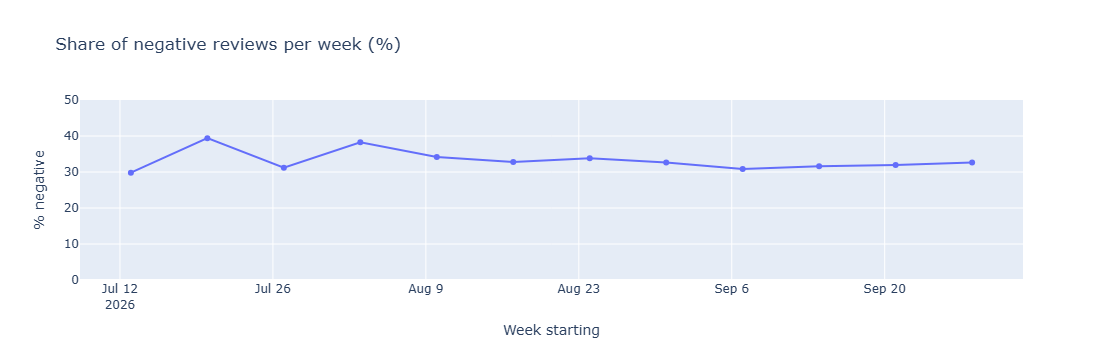

In [123]:
import plotly.express as px

d = final[(~final["partial_week"]) & (final["sentiment_pred"] != "not scored")]
wk = d.groupby("week_start").agg(reviews=("review_id", "size"),
                                 negative_pct=("sentiment_pred", lambda s: (s == "neg").mean() * 100)).reset_index()

fig = px.line(wk, x="week_start", y="negative_pct", markers=True, hover_data=["reviews"],
              title="Share of negative reviews per week (%)")
fig.update_layout(yaxis_title="% negative", xaxis_title="Week starting", yaxis_range=[0, 50])
fig.show()

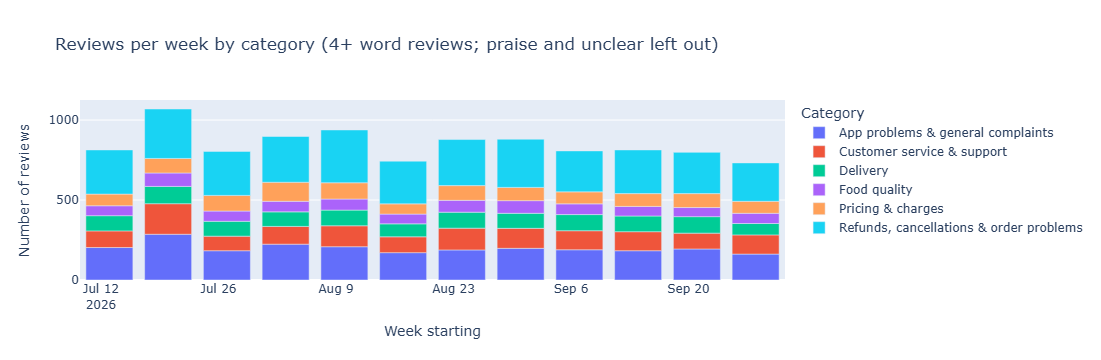

In [126]:
c = final[(~final["partial_week"]) &
          (~final["aspect"].isin(["No category (under 4 words)", "General praise", "Other / unclear"]))]
cnt = c.groupby(["week_start", "aspect"]).size().reset_index(name="reviews")

fig = px.bar(cnt, x="week_start", y="reviews", color="aspect",
             title="Reviews per week by category (4+ word reviews; praise and unclear left out)")
fig.update_layout(xaxis_title="Week starting", yaxis_title="Number of reviews", legend_title="Category")
fig.show()

In [130]:
## but first need to do for the short review also

In [132]:
short_neg = df[(df["n_words"] <= 3) & (df["language"] != "emoji_only") & (df["rating"] <= 2)]
print(len(short_neg))
print(short_neg["clean_text"].sample(40, random_state=1).to_string())

2678
37970              worst service
27291       quick delivery issue
24537                       nice
20255              worst service
6923                       great
8454         worst delivery app,
25560                       hshe
21469                oder only 1
6419                        good
13521     very expensive service
11041                       good
19158        pathetic experience
15744                   too late
37923                       okay
7566                       delay
29892           worst experience
18428                      worst
36753               very bad app
10092                   too late
15885                kachara hai
12363           pathetic service
19745                       good
6264                  disgusting
29993                  over rate
9561                    best app
14363                     okay 👍
13323             worst delivery
3255                         bad
10694                      worst
19150                  worst app
32922

In [134]:
# using topic modelling again

In [136]:
from sentence_transformers import SentenceTransformer
import numpy as np

short_neg = final[(final["n_words"] < 4) & (final["sentiment_pred"] == "neg")]
short_neg = short_neg[["review_id"]].merge(df[["review_id", "clean_text"]], on="review_id", how="left")
print("short negative reviews:", len(short_neg))

emb_model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", device="cuda")
short_emb = emb_model.encode(short_neg["clean_text"].tolist(), batch_size=128, show_progress_bar=True)

np.save("data/short_neg_embeddings.npy", short_emb)
short_neg[["review_id"]].to_csv("data/short_neg_ids.csv", index=False)
print(short_emb.shape)

short negative reviews: 2040


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

(2040, 384)


In [138]:
# so like in topic modelling we used MiniLM to convert reivew into number then using kmeans we got some category then using logistic reression trained the review with category

In [140]:
#now using that same trained model decided to get the category for the short term review also

In [144]:
import pandas as pd, numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

long_emb = np.load("data/long_review_embeddings.npy")
long_ids = pd.read_csv("data/long_review_ids.csv")
asp = pd.read_csv("data/review_aspects.csv")[["review_id", "aspect"]]
lr_df = long_ids[["review_id"]].merge(asp, on="review_id", how="left")
assert len(lr_df) == len(long_emb)

keep = (~lr_df["aspect"].isin(["General praise", "Other / unclear"]) & lr_df["aspect"].notna()).to_numpy()
X = long_emb[keep]
y = np.array(lr_df.loc[keep, "aspect"].astype(str).tolist())   # plain numpy strings
print("training reviews:", len(y))

X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
clf = LogisticRegression(max_iter=2000, class_weight="balanced")
clf.fit(X_tr, y_tr)
print("held-out accuracy on long reviews:", round(accuracy_score(y_va, clf.predict(X_va)), 3))
print(classification_report(y_va, clf.predict(X_va)))

short_emb = np.load("data/short_neg_embeddings.npy")
short_ids = pd.read_csv("data/short_neg_ids.csv")
proba = clf.predict_proba(short_emb)
short_ids["pred_aspect"] = clf.classes_[proba.argmax(axis=1)]
short_ids["confidence"] = proba.max(axis=1)
short_ids = short_ids.merge(df[["review_id", "clean_text"]], on="review_id", how="left")
print(short_ids["confidence"].describe().round(2))
print(short_ids["pred_aspect"].value_counts())

training reviews: 10684
held-out accuracy on long reviews: 0.921
                                         precision    recall  f1-score   support

      App problems & general complaints       0.95      0.95      0.95       497
             Customer service & support       0.87      0.92      0.89       306
                               Delivery       0.87      0.92      0.89       238
                           Food quality       0.89      0.94      0.92       173
                      Pricing & charges       0.90      0.98      0.94       216
Refunds, cancellations & order problems       0.96      0.88      0.92       707

                               accuracy                           0.92      2137
                              macro avg       0.91      0.93      0.92      2137
                           weighted avg       0.92      0.92      0.92      2137

count    2040.00
mean        0.97
std         0.10
min         0.34
25%         1.00
50%         1.00
75%         1.00
max

In [146]:
# 92% on long reviews is okay, but it’s not proof the categories are right. The categories came from KMeans on the same numbers, so the classifier is only learning to copy the clustering

In [148]:
pd.set_option("display.width", 120)
for cat in short_ids["pred_aspect"].unique():
    sub = short_ids[short_ids["pred_aspect"] == cat]
    print("\n===", cat, f"({len(sub)})")
    print(sub.sample(10, random_state=1)[["clean_text", "confidence"]].round(2).to_string(index=False))


=== Customer service & support (926)
               clean_text  confidence
        very bad delivery        0.57
                    worst        1.00
      bad service quality        1.00
pathetic customer service        1.00
      support is terrible        1.00
                     poor        1.00
         pathetic service        1.00
            worst support        1.00
    poor customer service        1.00
       waste support team        1.00

=== App problems & general complaints (259)
        clean_text  confidence
         worst app         1.0
         worst app         1.0
      bit slow app         1.0
         worst app         1.0
worst delivery app         1.0
      very bad app         1.0
      worst app 😡.         1.0
       dogshit app         1.0
         waste app         1.0
      very bad app         1.0

=== Refunds, cancellations & order problems (126)
             clean_text  confidence
                  waate        0.67
 no cancellation policy        1.00

In [150]:
# Generic words get forced into a category. “worst”, “poor”, “waste”, “waate” and “faltu 1” have no topic, but they got one anyway.

In [152]:
sample = short_ids.sample(120, random_state=2)[["review_id", "clean_text"]].copy()
sample["my_label"] = ""
sample.to_csv("data/short_cat_check_120.csv", index=False)
print(sample["clean_text"].to_string())

1665                              bad test
1171                    disgusting service
503                               not good
526                               very bad
1452                                 fraud
456                          delivery slow
1954                           retard stfu
376                                  shame
1523                                 waste
1202                    late to dispatched
1849                                 worst
649                          late delivery
1680                      slowest services
1990                          cancel order
600                                  worst
1332                         late delivery
1091                               vry bad
840                      very poor service
532           disappointing customer care.
1827                             worst aap
1962                                worst😡
284                                suckers
1884                           bad service
633        

In [154]:
### so fianlly

In [156]:
codes = {"REF": "Refunds, cancellations & order problems", "APP": "App problems & general complaints",
         "SUP": "Customer service & support", "DEL": "Delivery", "PRI": "Pricing & charges",
         "FOOD": "Food quality", "NONE": "No clear topic", "NOTCOMP": "Not a complaint"}

draft = {1665:"FOOD",1171:"SUP",503:"NONE",526:"NONE",1452:"APP",456:"DEL",1954:"NONE",376:"NONE",1523:"NONE",
1202:"DEL",1849:"NONE",649:"DEL",1680:"DEL",1990:"REF",600:"NONE",1332:"DEL",1091:"NONE",840:"SUP",532:"SUP",
1827:"APP",1962:"NONE",284:"NONE",1884:"SUP",633:"DEL",231:"NONE",1435:"DEL",1114:"NONE",1296:"NOTCOMP",
1018:"DEL",465:"APP",1484:"PRI",294:"APP",323:"NONE",781:"APP",1403:"SUP",862:"NONE",1220:"NONE",711:"SUP",
1841:"SUP",1025:"NONE",1260:"SUP",611:"NONE",1502:"SUP",645:"NONE",1153:"FOOD",370:"NONE",268:"NONE",
1586:"APP",909:"NONE",1563:"NONE",1648:"APP",2013:"NOTCOMP",1912:"DEL",1492:"NONE",1530:"DEL",459:"NONE",
263:"DEL",1468:"NONE",991:"NONE",1124:"DEL",352:"SUP",610:"NONE",1918:"PRI",123:"NONE",1795:"NONE",
1339:"APP",665:"PRI",4:"PRI",721:"PRI",1814:"REF",560:"NONE",1256:"DEL",1715:"NONE",112:"DEL",1799:"PRI",
1542:"NONE",1411:"PRI",137:"DEL",1352:"REF",920:"PRI",1709:"PRI",1980:"NONE",1462:"NONE",180:"APP",
1677:"SUP",1510:"REF",1580:"APP",677:"NOTCOMP",1268:"APP",1304:"PRI",71:"NONE",232:"NONE",481:"APP",
1166:"DEL",476:"DEL",1726:"DEL",278:"NONE",575:"APP",1796:"APP",1115:"APP",695:"APP",1722:"NONE",
1217:"PRI",1697:"NONE",101:"DEL",1922:"APP",1742:"SUP",1274:"APP",1341:"NONE",1505:"NONE",844:"SUP",
540:"SUP",372:"NONE",2035:"APP",1756:"DEL",1514:"SUP",1413:"NONE",448:"NONE",2023:"PRI",502:"APP"}

chk_s = pd.read_csv("data/short_cat_check_120.csv")
chk_s["my_label"] = [codes.get(draft.get(i, ""), "") for i in sample.index] if len(sample) == len(chk_s) else ""
print("labelled:", (chk_s["my_label"] != "").sum(), "of", len(chk_s))
chk_s.to_csv("data/short_cat_check_120_labelled.csv", index=False)
print(chk_s["my_label"].value_counts())

labelled: 120 of 120
my_label
No clear topic                             44
App problems & general complaints          20
Delivery                                   20
Customer service & support                 15
Pricing & charges                          12
Refunds, cancellations & order problems     4
Not a complaint                             3
Food quality                                2
Name: count, dtype: int64


In [158]:
cmp_s = chk_s.merge(short_ids[["review_id", "pred_aspect", "confidence"]], on="review_id", how="left")
cmp_s["match"] = cmp_s["my_label"] == cmp_s["pred_aspect"]
print("exact match:", round(cmp_s["match"].mean(), 3))

# only the reviews that have a real topic in my labels
topic = cmp_s[~cmp_s["my_label"].isin(["No clear topic", "Not a complaint"])]
print("reviews with a real topic:", len(topic), "| classifier right on them:", round(topic["match"].mean(), 3))

# how many 'No clear topic' ones did the classifier wrongly give a category
none = cmp_s[cmp_s["my_label"] == "No clear topic"]
print("No clear topic reviews:", len(none), "| classifier forced a category on all of them (it has no such class)")

print(pd.crosstab(cmp_s["my_label"], cmp_s["pred_aspect"]))

exact match: 0.433
reviews with a real topic: 73 | classifier right on them: 0.712
No clear topic reviews: 44 | classifier forced a category on all of them (it has no such class)
pred_aspect                              App problems & general complaints  Customer service & support  Delivery  \
my_label                                                                                                           
App problems & general complaints                                        9                           0         1   
Customer service & support                                               0                          15         0   
Delivery                                                                 0                           4        16   
Food quality                                                             0                           2         0   
No clear topic                                                           1                          34         4   
Not a com

In [162]:
#When a short review has a real topic (“late delivery”, “overcharge”), the model gets it right about 71% of the time. That’s fine.
#When it has no topic (“worst”, “bad”, “waste”), the model still forces a category, and most of them land in Customer service & support. That’s the main problem.

In [164]:
# so will retrain it again

In [166]:
done_ids = set(chk_s["review_id"])
pool = short_ids[~short_ids["review_id"].isin(done_ids)]
sample2 = pool.sample(300, random_state=5)[["review_id", "clean_text"]].copy()
sample2.to_csv("data/short_cat_check_300_more.csv", index=False)
print(sample2["clean_text"].reset_index(drop=True).to_string())

0                     scammer swiggy
1                       cheating app
2                        useless app
3                  charges very high
4                    bakwas delevery
5                        cancel karo
6                         price high
7                               poor
8                 very slow delivery
9                          no coupon
10         bade behaviour delvryboys
11                            wastee
12                           bad app
13                               not
14                           useless
15               spineless brand! 👎🏻
16                               bad
17                       not support
18            worst customer service
19                          not good
20                  pathetic service
21                       very costly
22                    bad experience
23                 late for delivery
24                               bad
25                          very bad
26                     late delivery
2

In [168]:
#labelling them

In [170]:
codes = {"REF": "Refunds, cancellations & order problems", "APP": "App problems & general complaints",
         "SUP": "Customer service & support", "DEL": "Delivery", "PRI": "Pricing & charges",
         "FOOD": "Food quality", "NONE": "No clear topic", "NOTCOMP": "Not a complaint"}

labs = """
APP APP APP PRI DEL REF PRI NONE DEL PRI
SUP NONE APP NONE NONE NONE NONE SUP SUP NONE
SUP PRI NONE DEL NONE NONE DEL NONE NONE APP
NONE NONE NONE PRI DEL APP NONE DEL NONE APP
DEL DEL NONE APP NONE NONE NONE NONE SUP REF
PRI APP DEL PRI DEL DEL NONE NONE APP DEL
APP PRI DEL NONE NONE APP NONE DEL DEL DEL
SUP NOTCOMP NONE PRI SUP DEL NONE NONE DEL NONE
REF NONE SUP NONE NONE DEL NONE REF NONE NONE
PRI DEL APP APP NONE PRI APP PRI PRI SUP
NONE NONE NONE PRI APP PRI NONE SUP FOOD SUP
APP APP APP NONE PRI DEL NONE SUP SUP SUP
SUP PRI NONE NOTCOMP APP NONE SUP NONE NOTCOMP DEL
DEL APP PRI SUP APP NONE DEL NONE DEL PRI
NONE APP DEL NONE NONE PRI NOTCOMP PRI NONE PRI
SUP SUP SUP NONE NONE APP NONE NONE DEL PRI
NONE NONE APP DEL NOTCOMP NONE PRI NONE NONE DEL
PRI APP SUP APP PRI NONE PRI NONE DEL NONE
NONE NONE NONE NOTCOMP DEL APP PRI NONE NONE APP
APP DEL NOTCOMP SUP APP NOTCOMP NONE DEL FOOD NONE
DEL NONE SUP APP SUP NONE SUP APP NONE NONE
NONE SUP NONE APP SUP APP APP APP SUP SUP
SUP NOTCOMP SUP SUP PRI DEL NONE SUP NONE NONE
DEL DEL DEL SUP DEL NONE SUP NONE NONE PRI
NONE PRI SUP NONE NONE PRI APP NONE APP DEL
APP APP DEL APP SUP APP NONE SUP NONE SUP
DEL NONE NONE APP PRI NONE SUP PRI DEL PRI
APP NONE NONE APP APP APP APP DEL APP NOTCOMP
DEL NONE APP NONE NONE NONE DEL DEL SUP DEL
NONE DEL DEL DEL SUP PRI NONE NONE SUP NONE
""".split()

s2 = pd.read_csv("data/short_cat_check_300_more.csv")
assert len(labs) == len(s2) == 300, (len(labs), len(s2))
s2["my_label"] = [codes[c] for c in labs]
s2.to_csv("data/short_cat_check_300_more_labelled.csv", index=False)
print(s2["my_label"].value_counts())

my_label
No clear topic                             103
App problems & general complaints           51
Delivery                                    51
Customer service & support                  43
Pricing & charges                           36
Not a complaint                             10
Refunds, cancellations & order problems      4
Food quality                                 2
Name: count, dtype: int64


In [172]:
# row number of each short review in the saved embeddings
ids_all = pd.read_csv("data/short_neg_ids.csv")["review_id"].tolist()
pos = {rid: i for i, rid in enumerate(ids_all)}
short_emb = np.load("data/short_neg_embeddings.npy")

train_s = pd.read_csv("data/short_cat_check_300_more_labelled.csv")   # 300 labelled, used for training
test_s  = pd.read_csv("data/short_cat_check_120_labelled.csv")        # 120 labelled, test only

Xs_tr = short_emb[[pos[r] for r in train_s["review_id"]]]
ys_tr = np.array(train_s["my_label"].astype(str).tolist())
Xs_te = short_emb[[pos[r] for r in test_s["review_id"]]]
ys_te = np.array(test_s["my_label"].astype(str).tolist())

# long reviews (X, y from the earlier cell) + the 300 short ones
X_all = np.vstack([X, Xs_tr])
y_all = np.concatenate([y, ys_tr])

has_topic = ~np.isin(ys_te, ["No clear topic", "Not a complaint"])
none_mask = ys_te == "No clear topic"

models = {}
for w in [1, 5, 10]:                       # how much more a short review counts than a long one
    sw = np.concatenate([np.ones(len(y)), np.full(len(ys_tr), w)])
    m = LogisticRegression(max_iter=3000, class_weight="balanced")
    m.fit(X_all, y_all, sample_weight=sw)
    pred = m.predict(Xs_te)
    models[w] = (m, pred)
    print(f"short-review weight {w}: overall {np.mean(pred == ys_te):.3f} | "
          f"on real-topic reviews {np.mean(pred[has_topic] == ys_te[has_topic]):.3f} | "
          f"caught 'No clear topic' {np.mean(pred[none_mask] == 'No clear topic'):.3f}")

print("\nold classifier on the same 120 for comparison: overall 0.433")
print(pd.crosstab(pd.Series(ys_te, name="my label"), pd.Series(models[5][1], name="predicted (weight 5)")))

short-review weight 1: overall 0.808 | on real-topic reviews 0.781 | caught 'No clear topic' 0.909
short-review weight 5: overall 0.817 | on real-topic reviews 0.808 | caught 'No clear topic' 0.886
short-review weight 10: overall 0.800 | on real-topic reviews 0.808 | caught 'No clear topic' 0.841

old classifier on the same 120 for comparison: overall 0.433
predicted (weight 5)                     App problems & general complaints  Customer service & support  Delivery  \
my label                                                                                                           
App problems & general complaints                                       15                           0         1   
Customer service & support                                               0                          15         0   
Delivery                                                                 0                           2        18   
Food quality                                                

In [174]:
# Big jump: 43% → about 82% on the same 120 reviews, and the model now catches almost 9 in 10 of the “No clear topic” ones.

In [176]:
# finally labelling

In [178]:
# final model: long reviews + all 420 labelled short ones, short weight = 5
X_fin = np.vstack([X, Xs_tr, Xs_te])
y_fin = np.concatenate([y, ys_tr, ys_te])
sw = np.concatenate([np.ones(len(y)), np.full(len(ys_tr) + len(ys_te), 5)])

final_clf = LogisticRegression(max_iter=3000, class_weight="balanced")
final_clf.fit(X_fin, y_fin, sample_weight=sw)

# label all 2,040 short negative reviews
short_out = pd.read_csv("data/short_neg_ids.csv")[["review_id"]].copy()
short_out["aspect"] = final_clf.predict(short_emb)
short_out["aspect"] = short_out["aspect"].replace({"Not a complaint": "No clear topic"})  # model never learned this one well

# join with the long-review categories (old file stays untouched)
long_part = pd.read_csv("data/review_aspects.csv")[["review_id", "aspect"]]
aspects_v2 = pd.concat([long_part, short_out], ignore_index=True)
assert aspects_v2["review_id"].is_unique
aspects_v2.to_csv("data/review_aspects_v2.csv", index=False)

print("rows:", len(aspects_v2))
print(short_out["aspect"].value_counts())

rows: 16437
aspect
No clear topic                             744
Customer service & support                 335
Delivery                                   334
App problems & general complaints          312
Pricing & charges                          233
Refunds, cancellations & order problems     48
Food quality                                34
Name: count, dtype: int64


In [181]:
#rebuild the dashboad.csv

In [183]:
final_v2 = final.drop(columns="aspect").merge(aspects_v2, on="review_id", how="left")
final_v2["aspect"] = final_v2["aspect"].fillna("Short positive (no topic)")
final_v2.loc[final_v2["sentiment_pred"] == "not scored", "aspect"] = "Emoji only (not scored)"

assert len(final_v2) == len(final) == 39457
final_v2.to_csv("data/dashboard_data_v2.csv", index=False)
print(final_v2["aspect"].value_counts())

aspect
Short positive (no topic)                  21889
Refunds, cancellations & order problems     3584
General praise                              2990
App problems & general complaints           2797
Customer service & support                  1866
Delivery                                    1523
Pricing & charges                           1312
Emoji only (not scored)                     1131
Food quality                                 898
No clear topic                               744
Other / unclear                              723
Name: count, dtype: int64


In [186]:
#lest see the one word reivew now

In [188]:
short_pos = final[(final["n_words"] < 4) & (final["sentiment_pred"] == "pos")]
print("short positive reviews:", len(short_pos))
s = short_pos[["review_id"]].merge(df[["review_id", "clean_text"]], on="review_id", how="left")
print(s["clean_text"].value_counts().head(25))
print(s["clean_text"].sample(40, random_state=3).to_string())

short positive reviews: 21889
clean_text
good                 6455
nice                 1848
super                 853
good 👍                849
ok                    696
very good             606
good service          489
best                  452
excellent             324
nice 👍                228
very nice             223
good app              215
good 😊                186
nice app              167
great                 137
awesome               106
best app              104
superb                102
very good 👍            84
gud                    83
wow                    82
very good service      79
good 👍🏻                76
thank you              71
good 👍😊                69
Name: count, dtype: int64
15941              good 👍
16763                best
9134              amezing
4761         good service
17766                good
8594                 good
10191             so good
11454                good
8831            excellent
20856             so nice
209                    

In [190]:
# rerun again

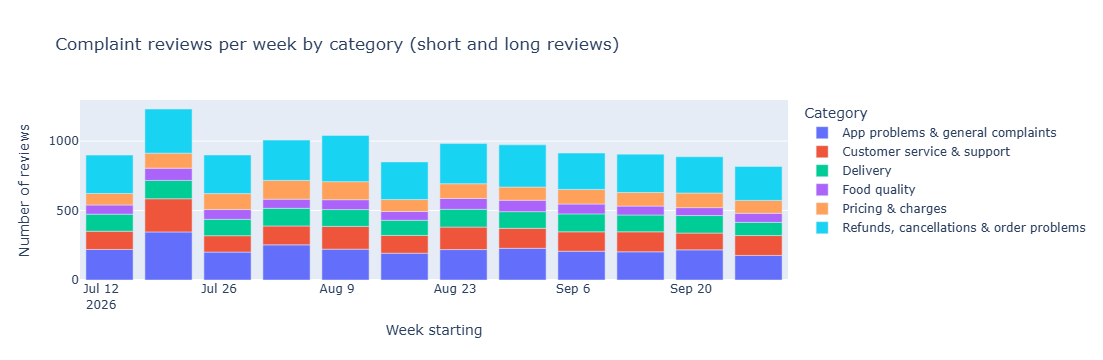

In [192]:
complaint_cats = ["Refunds, cancellations & order problems", "App problems & general complaints",
                  "Customer service & support", "Delivery", "Pricing & charges", "Food quality"]

c2 = final_v2[(~final_v2["partial_week"]) & (final_v2["aspect"].isin(complaint_cats))]
cnt2 = c2.groupby(["week_start", "aspect"]).size().reset_index(name="reviews")

fig = px.bar(cnt2, x="week_start", y="reviews", color="aspect",
             title="Complaint reviews per week by category (short and long reviews)")
fig.update_layout(xaxis_title="Week starting", yaxis_title="Number of reviews", legend_title="Category")
fig.show()

In [194]:
# aug vs sept

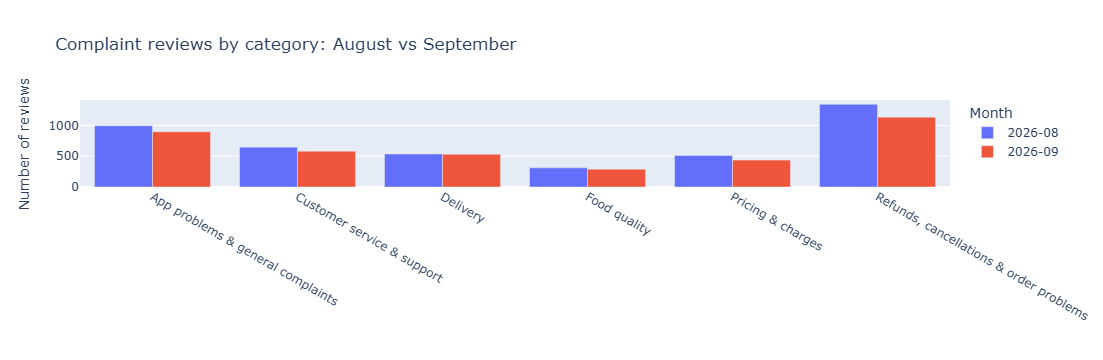

month                                    2026-08  2026-09  change_%
aspect                                                             
App problems & general complaints            994      896      -9.9
Customer service & support                   647      582     -10.0
Delivery                                     537      531      -1.1
Food quality                                 311      289      -7.1
Pricing & charges                            512      437     -14.6
Refunds, cancellations & order problems     1342     1134     -15.5

reviews in all months: {'2026-07': 9425, '2026-08': 13460, '2026-09': 13209, '2026-10': 3363}


In [196]:
m = final_v2[final_v2["month"].isin(["2026-08", "2026-09"]) & final_v2["aspect"].isin(complaint_cats)]
mc = m.groupby(["aspect", "month"]).size().reset_index(name="reviews")

fig = px.bar(mc, x="aspect", y="reviews", color="month", barmode="group",
             title="Complaint reviews by category: August vs September")
fig.update_layout(xaxis_title="", yaxis_title="Number of reviews", legend_title="Month")
fig.show()

piv = mc.pivot(index="aspect", columns="month", values="reviews")
piv["change_%"] = ((piv["2026-09"] - piv["2026-08"]) / piv["2026-08"] * 100).round(1)
print(piv)
print("\nreviews in all months:", final_v2.groupby("month").size().to_dict())

In [198]:
# sentiment by language

       language  reviews  negative_pct
0       english    36396          32.0
1  hindi_script      146          61.0
2      hinglish     1784          55.9


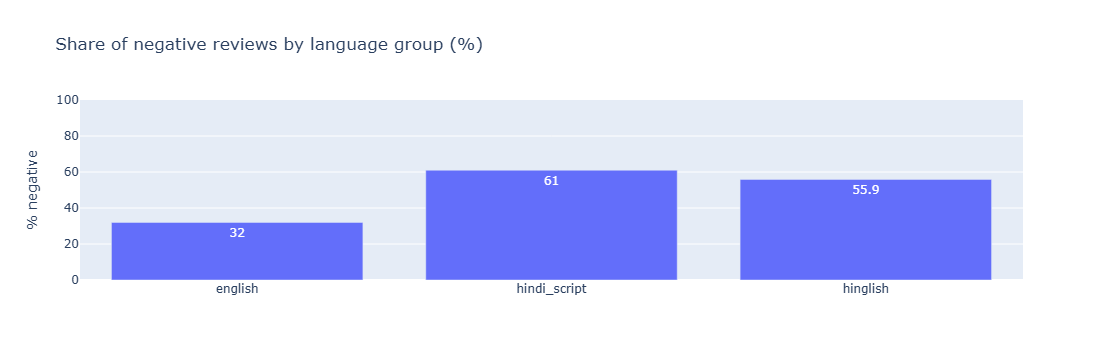

In [200]:
s = final_v2[final_v2["sentiment_pred"] != "not scored"]
lang = (s.groupby("language")
          .agg(reviews=("review_id", "size"),
               negative_pct=("sentiment_pred", lambda x: round((x == "neg").mean() * 100, 1)))
          .reset_index())
print(lang)

fig = px.bar(lang, x="language", y="negative_pct", text="negative_pct", hover_data=["reviews"],
             title="Share of negative reviews by language group (%)")
fig.update_layout(xaxis_title="", yaxis_title="% negative", yaxis_range=[0, 100])
fig.show()

      length  language  reviews  negative_pct
0  1-3 words   english    23438           8.4
1  1-3 words  hinglish      447          15.4
2        4-7   english     4250          45.3
3        4-7  hinglish      407          44.5
4       8-15   english     2645          72.3
5       8-15  hinglish      365          63.0
6        16+   english     6063          96.4
7        16+  hinglish      565          91.7


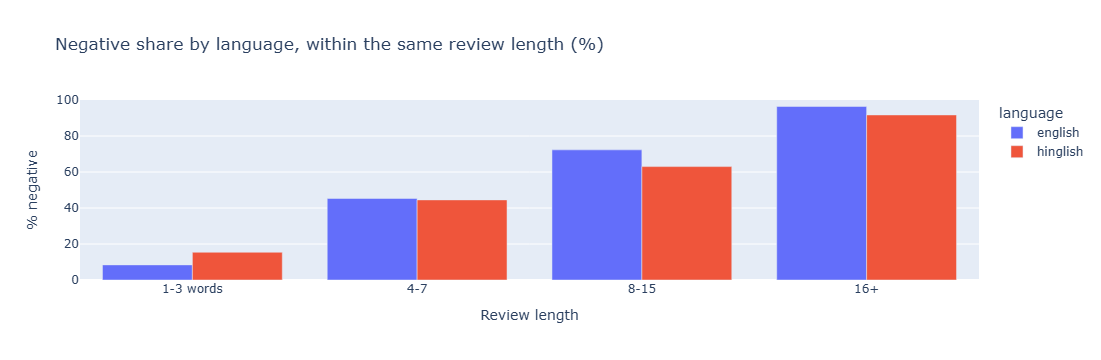

In [202]:
s = final_v2[(final_v2["sentiment_pred"] != "not scored") & (final_v2["language"].isin(["english", "hinglish"]))].copy()
s["length"] = pd.cut(s["n_words"], [0, 3, 7, 15, 10000], labels=["1-3 words", "4-7", "8-15", "16+"])

t = (s.groupby(["length", "language"], observed=True)
       .agg(reviews=("review_id", "size"),
            negative_pct=("sentiment_pred", lambda x: round((x == "neg").mean() * 100, 1)))
       .reset_index())
print(t)

fig = px.bar(t, x="length", y="negative_pct", color="language", barmode="group", hover_data=["reviews"],
             title="Negative share by language, within the same review length (%)")
fig.update_layout(xaxis_title="Review length", yaxis_title="% negative", yaxis_range=[0, 100])
fig.show()

In [204]:
# Hinglish reviews look more negative overall (56% vs 32%), but this is mostly because they’re longer. Within the same length, the two are similar

In [206]:
# category share

                                  category  share_%
0  Refunds, cancellations & order problems     29.8
1        App problems & general complaints     23.5
2               Customer service & support     15.5
3                                 Delivery     12.7
4                        Pricing & charges     11.0
5                             Food quality      7.4


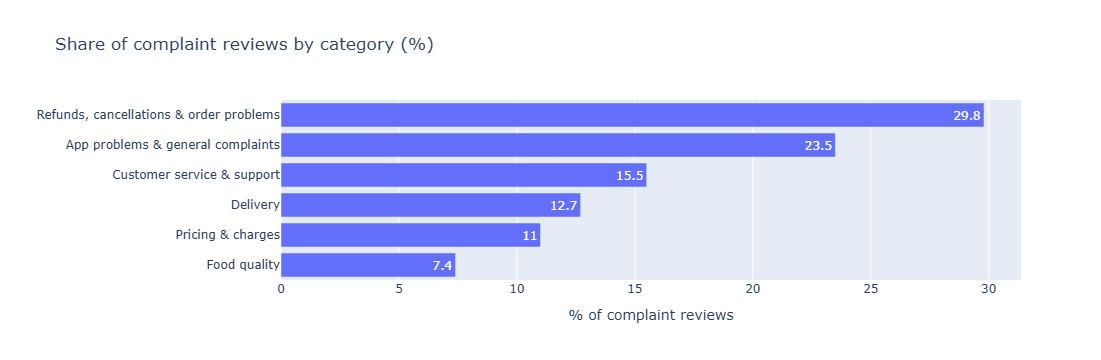

In [208]:
full = final_v2[(~final_v2["partial_week"]) & final_v2["aspect"].isin(complaint_cats)]
share = (full["aspect"].value_counts(normalize=True) * 100).round(1).reset_index()
share.columns = ["category", "share_%"]
print(share)

fig = px.bar(share, x="share_%", y="category", orientation="h", text="share_%",
             title="Share of complaint reviews by category (%)")
fig.update_layout(xaxis_title="% of complaint reviews", yaxis_title="", yaxis={"categoryorder": "total ascending"})
fig.show()

In [5]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# reload from saved files (kernel was restarted)
df = pd.read_csv("data/reviews_with_language.csv")                 # has clean_text
final_v2 = pd.read_csv("data/dashboard_data_v2.csv")               # has aspect, week_start
print(df.shape, final_v2.shape, "clean_text" in df.columns)

cats6 = ["Refunds, cancellations & order problems", "App problems & general complaints",
         "Customer service & support", "Delivery", "Pricing & charges", "Food quality"]

w = df[["review_id", "clean_text"]].merge(final_v2[["review_id", "aspect", "week_start"]], on="review_id")
w = w[w["aspect"].isin(cats6)].reset_index(drop=True)
texts = w["clean_text"].astype(str).tolist()

stop = set("the a an to of and is it in for on my me i this that was you are have has with at be so as but or they them we our your from its im".split())
cv = CountVectorizer(ngram_range=(2, 2), min_df=15)
Xw = cv.fit_transform(texts)
terms = np.array(cv.get_feature_names_out())
keep = np.array([not all(p in stop for p in t.split()) for t in terms])
Xw, terms = Xw[:, keep], terms[keep]

weeks_all = sorted(w["week_start"].unique())
out = []
for a in cats6:
    ma = (w["aspect"] == a).to_numpy()
    totals = np.asarray(Xw[ma].sum(axis=0)).ravel()
    top = np.argsort(-totals)[:60]
    for wk in weeks_all:
        m = (ma & (w["week_start"] == wk).to_numpy())
        if m.sum() == 0:
            continue
        cnt = np.asarray(Xw[m][:, top].sum(axis=0)).ravel()
        for j, c in zip(top, cnt):
            if c > 0:
                out.append((a, str(wk), terms[j], int(c)))

words = pd.DataFrame(out, columns=["aspect", "week_start", "phrase", "count"])
words.to_csv("data/category_phrases.csv", index=False)
print(words.shape)
for a in cats6:
    print(a, "->", words[words["aspect"] == a].groupby("phrase")["count"].sum().nlargest(8).to_dict())

(39457, 16) (39457, 11) True
(4208, 4)
Refunds, cancellations & order problems -> {'the order': 763, 'my order': 601, 'customer support': 433, 'the delivery': 373, 'order and': 308, 'delivery partner': 301, 'customer care': 297, 'with swiggy': 293}
App problems & general complaints -> {'this app': 745, 'worst app': 687, 'the app': 338, 'the worst': 234, 'the order': 207, 'very bad': 206, 'customer support': 189, 'app ever': 188}
Customer service & support -> {'customer service': 304, 'very bad': 239, 'customer support': 238, 'worst service': 197, 'customer care': 169, 'worst customer': 169, 'bad service': 116, 'very poor': 110}
Delivery -> {'delivery time': 166, 'the delivery': 151, 'the order': 147, 'on time': 111, 'delivery partner': 110, 'late delivery': 105, 'to deliver': 93, 'more than': 89}
Pricing & charges -> {'too much': 99, 'delivery charges': 86, 'very high': 73, 'too high': 59, 'extra charges': 50, 'charges are': 49, 'is too': 38, 'is not': 36}
Food quality -> {'the food': 

In [7]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

cats6 = ["Refunds, cancellations & order problems", "App problems & general complaints",
         "Customer service & support", "Delivery", "Pricing & charges", "Food quality"]

w = df[["review_id", "clean_text"]].merge(final_v2[["review_id", "aspect", "week_start"]], on="review_id")
w = w[w["aspect"].isin(cats6)].reset_index(drop=True)
texts = w["clean_text"].astype(str).tolist()

stop = set("the a an to of and is it in for on my me i this that was you are have has with at be so as but or they them we our your from its im".split())
cv = CountVectorizer(ngram_range=(2, 2), min_df=15)
Xw = cv.fit_transform(texts)
terms = np.array(cv.get_feature_names_out())
keep = np.array([not all(p in stop for p in t.split()) for t in terms])
Xw, terms = Xw[:, keep], terms[keep]

weeks_all = sorted(w["week_start"].unique())
out = []
for a in cats6:
    ma = (w["aspect"] == a).to_numpy()
    totals = np.asarray(Xw[ma].sum(axis=0)).ravel()
    top = np.argsort(-totals)[:60]
    for wk in weeks_all:
        m = (ma & (w["week_start"] == wk).to_numpy())
        if m.sum() == 0:
            continue
        cnt = np.asarray(Xw[m][:, top].sum(axis=0)).ravel()
        for j, c in zip(top, cnt):
            if c > 0:
                out.append((a, str(wk), terms[j], int(c)))

words = pd.DataFrame(out, columns=["aspect", "week_start", "phrase", "count"])
words.to_csv("data/category_phrases.csv", index=False)
print(words.shape)
for a in cats6:
    print(a, "->", words[words["aspect"] == a].groupby("phrase")["count"].sum().nlargest(8).to_dict())

(4208, 4)
Refunds, cancellations & order problems -> {'the order': 763, 'my order': 601, 'customer support': 433, 'the delivery': 373, 'order and': 308, 'delivery partner': 301, 'customer care': 297, 'with swiggy': 293}
App problems & general complaints -> {'this app': 745, 'worst app': 687, 'the app': 338, 'the worst': 234, 'the order': 207, 'very bad': 206, 'customer support': 189, 'app ever': 188}
Customer service & support -> {'customer service': 304, 'very bad': 239, 'customer support': 238, 'worst service': 197, 'customer care': 169, 'worst customer': 169, 'bad service': 116, 'very poor': 110}
Delivery -> {'delivery time': 166, 'the delivery': 151, 'the order': 147, 'on time': 111, 'delivery partner': 110, 'late delivery': 105, 'to deliver': 93, 'more than': 89}
Pricing & charges -> {'too much': 99, 'delivery charges': 86, 'very high': 73, 'too high': 59, 'extra charges': 50, 'charges are': 49, 'is too': 38, 'is not': 36}
Food quality -> {'the food': 76, 'food is': 61, 'good food

In [9]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

df = pd.read_csv("data/reviews_with_language.csv")
final_v2 = pd.read_csv("data/dashboard_data_v2.csv")

cats6 = ["Refunds, cancellations & order problems", "App problems & general complaints",
         "Customer service & support", "Delivery", "Pricing & charges", "Food quality"]

w = df[["review_id", "clean_text"]].merge(final_v2[["review_id", "aspect", "week_start"]], on="review_id")
w = w[w["aspect"].isin(cats6)].reset_index(drop=True)
texts = w["clean_text"].astype(str).tolist()

stop = set("""the a an to of and is it in for on my me i this that was you are have has with at be so as but or they
them we our your from its im am been were will would can could do did does not no very too just get got
hai ka ki ke ko se me ye yeh to hi bhi h ho hain mera mere mai main kar kya aur ya hum tum ap aap
swiggy swigy sweggy app""".split())

cv = CountVectorizer(ngram_range=(2, 2), min_df=15)
Xw = cv.fit_transform(texts)
terms = np.array(cv.get_feature_names_out())
keep = np.array([not any(p in stop for p in t.split()) for t in terms])
Xw, terms = Xw[:, keep], terms[keep]
print("phrases left after removing filler:", len(terms))

n_docs = {a: int((w["aspect"] == a).sum()) for a in cats6}
tot = {a: np.asarray(Xw[(w["aspect"] == a).to_numpy()].sum(axis=0)).ravel() for a in cats6}
all_tot = sum(tot.values())
N = sum(n_docs.values())

weeks_all = sorted(w["week_start"].unique())
out = []
for a in cats6:
    rate = tot[a] / n_docs[a]
    other = (all_tot - tot[a]) / (N - n_docs[a])
    lift = (rate + 1e-4) / (other + 1e-4)
    ok = np.where((tot[a] >= 15) & (lift >= 1.5))[0]
    top = ok[np.argsort(-tot[a][ok])][:40]
    ma = (w["aspect"] == a).to_numpy()
    for wk in weeks_all:
        m = ma & (w["week_start"] == wk).to_numpy()
        if m.sum() == 0 or len(top) == 0:
            continue
        cnt = np.asarray(Xw[m][:, top].sum(axis=0)).ravel()
        for j, c in zip(top, cnt):
            if c > 0:
                out.append((a, str(wk), terms[j], int(c)))

words2 = pd.DataFrame(out, columns=["aspect", "week_start", "phrase", "count"])
words2.to_csv("data/category_phrases_v2.csv", index=False)
print(words2.shape)
for a in cats6:
    print("\n", a, "->", words2[words2["aspect"] == a].groupby("phrase")["count"].sum().nlargest(8).to_dict())

phrases left after removing filler: 558
(1730, 4)

 Refunds, cancellations & order problems -> {'customer support': 433, 'delivery partner': 301, 'customer care': 297, 'worst experience': 147, 'disappointing experience': 141, 'bad experience': 136, 'ordered food': 135, 'cancellation fee': 134}

 App problems & general complaints -> {'food delivery': 162, 'worst food': 105, 'don use': 97, 'order food': 58, 'worst delivery': 58, 'please don': 48, 'don order': 43, 'better than': 39}

 Customer service & support -> {'customer service': 304, 'customer support': 238, 'worst service': 197, 'customer care': 169, 'worst customer': 169, 'bad service': 116, 'poor service': 88, 'worst experience': 84}

 Delivery -> {'delivery time': 166, 'delivery partner': 110, 'late delivery': 105, 'more than': 89, '30 minutes': 48, 'fast delivery': 38, 'always late': 35, 'worst delivery': 31}

 Pricing & charges -> {'delivery charges': 86, 'extra charges': 50, 'platform fee': 30, 'delivery charge': 26, 'high pr

In [11]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

df = pd.read_csv("data/reviews_with_language.csv")
final_v2 = pd.read_csv("data/dashboard_data_v2.csv")

cats6 = ["Refunds, cancellations & order problems", "App problems & general complaints",
         "Customer service & support", "Delivery", "Pricing & charges", "Food quality"]

w = df[["review_id", "clean_text"]].merge(
    final_v2[["review_id", "aspect", "week_start", "sentiment_pred"]], on="review_id")
w = w[w["aspect"].isin(cats6) & (w["sentiment_pred"] == "neg")].reset_index(drop=True)   # complaints only
print("negative reviews with a category:", len(w))
texts = w["clean_text"].astype(str).tolist()

stop = set("""the a an to of and is it in for on my me i this that was you are have has with at be so as but or they
them we our your from its im am been were will would can could do did does not no very too just get got
hai ka ki ke ko se me ye yeh to hi bhi h ho hain mera mere mai main kar kya aur ya hum tum ap aap
swiggy swigy sweggy app don than more please ever seen good best great nice love""".split())

cv = CountVectorizer(ngram_range=(2, 2), min_df=10)
Xw = cv.fit_transform(texts)
terms = np.array(cv.get_feature_names_out())
keep = np.array([not any(p in stop for p in t.split()) for t in terms])
Xw, terms = Xw[:, keep], terms[keep]

n_docs = {a: int((w["aspect"] == a).sum()) for a in cats6}
tot = {a: np.asarray(Xw[(w["aspect"] == a).to_numpy()].sum(axis=0)).ravel() for a in cats6}
all_tot = sum(tot.values())
N = sum(n_docs.values())

weeks_all = sorted(w["week_start"].unique())
out = []
for a in cats6:
    rate = tot[a] / n_docs[a]
    other = (all_tot - tot[a]) / (N - n_docs[a])
    lift = (rate + 1e-4) / (other + 1e-4)
    ok = np.where((tot[a] >= 10) & (lift >= 2.0))[0]
    top = ok[np.argsort(-tot[a][ok])][:40]
    ma = (w["aspect"] == a).to_numpy()
    for wk in weeks_all:
        m = ma & (w["week_start"] == wk).to_numpy()
        if m.sum() == 0 or len(top) == 0:
            continue
        cnt = np.asarray(Xw[m][:, top].sum(axis=0)).ravel()
        for j, c in zip(top, cnt):
            if c > 0:
                out.append((a, str(wk), terms[j], int(c)))

words3 = pd.DataFrame(out, columns=["aspect", "week_start", "phrase", "count"])
words3.to_csv("data/category_phrases_v3.csv", index=False)
print(words3.shape)
for a in cats6:
    print("\n", a, "->", words3[words3["aspect"] == a].groupby("phrase")["count"].sum().nlargest(8).to_dict())

negative reviews with a category: 11145
(1705, 4)

 Refunds, cancellations & order problems -> {'delivery partner': 299, 'disappointing experience': 141, 'ordered food': 135, 'cancellation fee': 134, 'even after': 112, 'delivery boy': 107, 'support team': 70, 'order cancel': 69}

 App problems & general complaints -> {'food delivery': 162, 'worst food': 105, 'order food': 58, 'worst delivery': 58, 'never use': 35, 'other apps': 31, 'deliver food': 29, 'worst application': 28}

 Customer service & support -> {'customer service': 304, 'worst service': 197, 'worst customer': 169, 'bad service': 116, 'poor service': 88, 'pathetic service': 70, 'poor customer': 55, 'pathetic customer': 38}

 Delivery -> {'delivery time': 158, 'late delivery': 105, '30 minutes': 48, 'always late': 35, '20 minutes': 30, 'delivery service': 29, 'much time': 28, '15 minutes': 27}

 Pricing & charges -> {'delivery charges': 82, 'extra charges': 47, 'platform fee': 30, 'delivery charge': 24, 'high price': 24, 'de

In [13]:
import re
import pandas as pd

df = pd.read_csv("data/reviews_with_language.csv")
fv = pd.read_csv("data/dashboard_data_v2.csv")

m = df[["review_id", "clean_text"]].merge(
    fv[["review_id", "date", "rating", "language", "n_words", "aspect", "sentiment_pred"]], on="review_id")
m = m[(m["n_words"] >= 4) & (m["n_words"] <= 60) & (m["sentiment_pred"] != "not scored")]

def mask(t):
    t = re.sub(r"\S+@\S+", "[email]", t)             # emails
    t = re.sub(r"\+?\d[\d\s\-]{7,}\d", "[number]", t)  # phone numbers
    t = re.sub(r"\b\d{6,}\b", "[number]", t)           # long ids
    t = re.sub(r"@\w+", "[user]", t)                   # handles
    return t

def intro(t):                                          # drop reviews that look like someone naming themselves
    return bool(re.search(r"\b(my name|name is|mr|mrs|ms)\b", t))

m["text"] = m["clean_text"].astype(str).apply(mask)
m = m[~m["text"].apply(intro)]

parts = []
for lg, n in [("english", 200), ("hinglish", 90), ("hindi_script", 10)]:
    pool = m[m["language"] == lg]
    parts.append(pool.sample(min(n, len(pool)), random_state=1))
s = pd.concat(parts)[["review_id", "date", "rating", "language", "aspect", "sentiment_pred", "text"]]
s.to_csv("data/review_sample_masked.csv", index=False)

print(len(s), s["language"].value_counts().to_dict())
print(s["text"].sample(40, random_state=2).to_string())

300 {'english': 200, 'hinglish': 90, 'hindi_script': 10}
32946    worst experience my order cost is 362 i asked ...
38370    i ordered a pancake 129 and then sab chij mila...
22942    instamart is just pathetic. they always show f...
35930          paise kyun badhaye 256tha to 270 kyun kiyaa
24315    recently swiggy app has issues. even though re...
34490    ujjain mein sanvariya sandwich ka test bahut s...
24175                                enjoy with swiggy 🙌🏻💗
6592     i ordered kurkure 30 pics but received 21 . wh...
28071              option easy way இருந்தா நல்லா இருக்கும்
4422                          cash on delivery verry best.
11482                                      nice work 👏 👌 👍
39439      food good not sent bowl and spoon how to adjust
29056                              never delivered on time
2852     acche hai par bahut sare delivery partner assi...
22956                         most items are not available
37568    delivery boy is so rude in call and not delive...

In [16]:
import pandas as pd

df = pd.read_csv("data/reviews_with_language.csv")
test = pd.read_csv("data/sentiment_test_300_labelled.csv", encoding="utf-8-sig")
test["sentiment"] = test["sentiment"].astype(str).str.strip().str.lower()

train_pool = df[~df["review_id"].isin(test["review_id"]) & (df["language"] != "emoji_only")].copy()
train_pool = train_pool[~train_pool["clean_text"].isin(set(test["clean_text"]))]
train_pool["label"] = train_pool["rating"].map({1: 0, 2: 0, 4: 1, 5: 1})   # 0 = neg, 1 = pos
train_pool = train_pool.dropna(subset=["label"])
train_pool["label"] = train_pool["label"].astype(int)

print(len(train_pool), train_pool["label"].value_counts().to_dict())

23538 {0: 12022, 1: 11516}


In [18]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
tr_idx, va_idx = next(gss.split(train_pool, groups=train_pool["clean_text"]))
tr_df = train_pool.iloc[tr_idx].reset_index(drop=True)
va_df = train_pool.iloc[va_idx].reset_index(drop=True)

print("train:", len(tr_df), tr_df["label"].value_counts().to_dict())
print("validation:", len(va_df), va_df["label"].value_counts().to_dict())

train: 18885 {0: 9680, 1: 9205}
validation: 4653 {0: 2342, 1: 2311}
